# Four-wave-mixing tones as GRAPE controls: method and Stage 2

**Purpose.** `dissipation_grape.ipynb` trains logical gates on the Shirol odd kitten code with an exact
open-system cost. Its d2 X gate (§11 there) reaches $F_{\rm pro} = 0.9556$. About 3.6 % of the loss is
dissipation, and no shape of the two linear drives (cavity and transmon) can remove it. A lost storage photon can only
be put back if the information about the loss is thrown away somewhere. On this chip the only fast place to throw it
is the readout resonator.

PReSPA (Shirol et al., PRX 16, 021042 (2026)) reaches the readout with two **four-wave-mixing (FWM)** combs. These are
pump tones on the transmon that swap excitations between modes through the junction's nonlinearity:

- **comb 1** puts a lost photon back and parks the transmon in $|f\rangle$: $|n{-}1,g,0\rangle \to |n,f,0\rangle$;
- **comb 2** empties the transmon into the readout, $|n,f,0\rangle \to |n,g,1\rangle$, and the readout photon then
  leaks away.

`fwm_tuning.ipynb` built the model of one such tone on the same drift as DGRAPE. This notebook makes **the pump
displacement $\beta_k(t)$ of every tone a GRAPE control**, next to the four linear-drive quadratures. It writes up the
method, checks every piece against something independent, and reports **Stage 2**: the d2 gate frozen, only the
tones optimized.

**Answer in one line.** With the d2 gate frozen, the tones cannot help. All four Stage 2 runs, from starts as far apart as $F = 0.70$ and $0.955$, end at the same pulse with almost no tones ($\max|\beta_k| = 0.003$, comb 1 switched off). They score $F_{\rm pro} = 0.955561$ against $0.955554$ with tones off: a gain of $6\times10^{-6}$, 500 times below the 0.3 % go threshold. This is the null result §6.2 predicted. It does not rule out Stage 3, where the gate may change too. **With the full comb (§7, 18 teeth)** the answer is the same: the best of four runs gains $2.2\times10^{-5}$ ($F_{\rm pro} = 0.955576$), 140 times below the threshold, and the gain is coherent ($3.7\times10^{-5}$ in the closed system), not a repair: the photon-loss cost does not move.

| § | content |
|---|---|
| 1 | why FWM controls: where d2 loses fidelity, **when** the losses happen, how fast PReSPA corrects |
| 2 | the combined Hamiltonian, **how strong a tone can usefully be** (Stark limit), pump mixing |
| 3 | the controls and their limits: $\lvert\beta_k\rvert \le 0.1$, band ±2 MHz, about 60 degrees of freedom |
| 4 | sub-time-steps: why the FWM terms need them, CF4 scheme, five checks, cost, the exact gradient |
| 5 | the cost functions, scored at the end of the gate |
| 6 | **Stage 2**: baselines, a prediction, landscape scan, four L-BFGS-B runs, held-out scoring, verdict |
| 7 | **the full comb**: 9 teeth per comb (18 tones, every repair $n{-}1 \to n$ up to $8 \to 9$), Stage 2 rerun |
| 8 | Stage 3 (linear drives and tones together): protocol, revised by Stage 2 |
| 9–11 | checklist, open decisions, review log of this revision |

**Code.** The model and its exact gradient live in `DGRAPE/fwm.py`. Tests are in `validation/test_fwm_grape.py`
(15 tests, about two minutes). The scripts are `DGRAPE/fwm_stage2_scan.py` (scan), `DGRAPE/train_fwm.py` (training)
and `DGRAPE/fwm_score.py` (held-out scoring). Training is never rerun here; §6 and §7 load the saved results from
`pulses/dgrape/*X_fwm_s2*` and `tables/fwm_stage2_*.csv`. §2–§6 describe Shirol's six tones; the scripts and
`DGRAPE/fwm.py` take the tone set as a parameter (`paths`), which §7 uses for 18.

**Same model as the two parent notebooks.** Same chip (Shirol Table I, `AQEC/device.py`) and drift
(`DGRAPE.model.drift_hamiltonian`, higher-order terms on). Same frame, rotating at the linear mode frequencies
$\omega_a, \omega_q, \omega_r$. Same space: storage × transmon (g, e, f) × readout. States are written
$|n, j, m\rangle$ = (storage photons, transmon level, readout photons). Signs follow Shirol: $\alpha$ and every $\chi$
are stored positive, with explicit minus signs in the Hamiltonian.

**Words used below.** *Pre-image*: the raw optimizer variable $x$, before the band filter and the ramp turn it into
the physical pulse. *Costate*: the backward-propagated derivative of the cost with respect to the state, used by the
exact gradient. *CF4*: a fourth-order commutator-free Magnus integrator (§4.2). *Held-out*: a scoring condition the
pulse was not trained on.

In [1]:
import glob
import json
import os
import sys
import time

REPO_ROOT = os.path.abspath(".")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from IPython.display import display

from AQEC import device as dev
from AQEC import master_equation as me
from DGRAPE.model import Model, operators, index
import DGRAPE.lindblad_np as lnp
from DGRAPE.code import process_targets, embedded_basis, process_fidelity_from_outputs
from DGRAPE import fwm
from core.fourier_cutoff import make_band_mask

# Apple's Accelerate BLAS raises spurious divide/overflow warnings on ordinary complex
# matmuls (no actual NaN/Inf; see core/grape_core.py). Harmless elsewhere.
np.seterr(divide="ignore", over="ignore", invalid="ignore")

TWO_PI = 2 * np.pi
G, E, F = 0, 1, 2
DT = 0.002                                   # us, the DGRAPE control grid (2 ns)
U_D2 = np.load("pulses/dgrape/u_X_open_d2.npy")    # the frozen gate of Stage 2, shape (550, 4)
N_D2 = U_D2.shape[0]
os.makedirs("figures", exist_ok=True)

OKABE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"]


def tidy(ax, grid=True):
    # House style (aqec_experiments.ipynb, fwm_tuning.ipynb): recessive grid, no top/right spines.
    if grid:
        ax.grid(color="0.9", lw=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def mhz(w):
    return w / TWO_PI


print(f"d2 pulse: N = {N_D2}, dt = {DT * 1e3:.0f} ns, duration {N_D2 * DT:.2f} us")

d2 pulse: N = 550, dt = 2 ns, duration 1.10 us


# 1. Why FWM controls

## 1.1 Where the d2 gate loses fidelity

`dissipation_grape.ipynb` §11.3 splits the d2 gate's error into a coherent part (0.9 %) and dissipation (3.6 %).
The cell below splits the dissipation further, by switching on one decay channel at a time. It runs at the training
truncation $n_c = 16$ with the readout cut to one level ($n_r = 1$). That is exact here, because nothing drives the
readout in d2 (tested in DGRAPE, §2.3 there). `fwm.model_with_channels(n_c, n_r, keep)` builds a model whose jump
operators are only those named in `keep`: `a` (storage loss), `r` (readout loss), and `s_ge`, `s_ef` (transmon
decay).

In [2]:
N_C_SPLIT = 16
E16, T16, W16 = process_targets("X", N_C_SPLIT, n_r=1)
split = {}
for label, keep in [("closed (no dissipation)", set()), ("storage photon loss only", {"a"}),
                    ("transmon T1 only", {"s_ge", "s_ef"}), ("all decay (training model)", None)]:
    R = lnp.propagate(fwm.model_with_channels(N_C_SPLIT, 1, keep), U_D2, E16, DT)
    split[label] = process_fidelity_from_outputs(R, T16, W16)
F_closed = split["closed (no dissipation)"]
split_table = pd.DataFrame({"F_pro": split, "cost vs closed": {k: F_closed - v for k, v in split.items()}})
display(split_table.style.format({"F_pro": "{:.5f}", "cost vs closed": "{:.4f}"})
        .set_caption(f"Table 1. The d2 X gate at n_c = {N_C_SPLIT}, one decay channel at a time "
                     "(higher-order terms on, n_r = 1)."))

,F_pro,cost vs closed
closed (no dissipation),0.99107,0.0000
storage photon loss only,0.96711,0.0240
transmon T1 only,0.97922,0.0119
all decay (training model),0.95555,0.0355


**Reading Table 1.**

- **Storage photon loss costs 2.4 %, two thirds of the dissipation.** Transmon decay costs 1.2 %. The two add up to
  the "all decay" row (3.55 %) to within their small overlap. The closed gate reaches 0.991.
- **The linear drives cannot fix the photon-loss part.** A loss carries information out of the system, and undoing
  it needs a place to dump that information (an *entropy sink*). The transmon is too slow for that ($T_1$ = 50 μs).
  The readout is fast, $1/\kappa_r = 0.27$ μs, but in d2 nothing couples the storage or the transmon to it. FWM tones
  do.
- **The transmon part is out of scope here.** FWM tones do not correct transmon decay. `dissipation_grape.ipynb` §12
  reduces it with a transmon-excitation penalty instead.

## 1.2 How fast PReSPA corrects

A correction is a three-step chain. Comb 1 swaps $|n{-}1,g,0\rangle \to |n,f,0\rangle$, comb 2 swaps
$|n,f,0\rangle \to |n,g,1\rangle$, and the readout photon leaks out at $\kappa_r$. Shirol's Eq. (B2) turns that chain
into a 3×3 non-Hermitian matrix whose slowest decay rate is the correction rate
(`AQEC.master_equation.b2_correction_rate`). The cell evaluates it at Shirol's Table II rates, and at the best
second-comb rate for a series of stronger first-comb rates.

In [3]:
r_paper, _ = me.b2_correction_rate(dev.OMEGA_1, dev.OMEGA_2)
o1_grid = TWO_PI * np.array([0.055, 0.2, 0.5, 1.0, 2.0])
o2_grid = TWO_PI * np.linspace(0.02, 3.0, 300)
rate_map, _ = me.correction_rate_map(o1_grid, o2_grid)
rows = [{"Omega_1/2pi (kHz)": 1e3 * mhz(dev.OMEGA_1), "Omega_2/2pi (kHz)": 1e3 * mhz(dev.OMEGA_2),
         "correction rate (1/us)": r_paper, "time per correction (us)": 1 / r_paper, "note": "Shirol Table II"}]
for i, o1 in enumerate(o1_grid):
    k = np.argmax(rate_map[i])
    rows.append({"Omega_1/2pi (kHz)": 1e3 * mhz(o1), "Omega_2/2pi (kHz)": 1e3 * mhz(o2_grid[k]),
                 "correction rate (1/us)": rate_map[i, k], "time per correction (us)": 1 / rate_map[i, k],
                 "note": "best Omega_2"})
display(pd.DataFrame(rows).style.hide(axis="index")
        .format({"Omega_1/2pi (kHz)": "{:.0f}", "Omega_2/2pi (kHz)": "{:.0f}",
                 "correction rate (1/us)": "{:.2f}", "time per correction (us)": "{:.2f}"})
        .set_caption("Table 2. PReSPA correction rate of one path (Eq. B2), at Table II and at stronger comb-1 rates."))
print(f"kappa_r / 2 = {dev.kappa_r / 2:.2f} /us;  gate duration {N_D2 * DT:.2f} us;  "
      f"photon-loss rate of the code 3 kappa_a = {3 * dev.kappa_a:.4f} /us")

Omega_1/2pi (kHz),Omega_2/2pi (kHz),correction rate (1/us),time per correction (us),note
55,160,0.36,2.77,Shirol Table II
55,160,0.37,2.68,best Omega_2
200,239,0.96,1.05,best Omega_2
500,409,1.15,0.87,best Omega_2
1000,738,1.19,0.84,best Omega_2
2000,1435,1.21,0.83,best Omega_2


kappa_r / 2 = 1.82 /us;  gate duration 1.10 us;  photon-loss rate of the code 3 kappa_a = 0.0221 /us


**Reading Table 2.**

- **At Table II a correction takes about 2.8 μs**, longer than the 1.1 μs gate.
- **Pumping constant tones harder does not make them much faster.** The rate saturates near 1.2 μs⁻¹ (0.8 μs per
  correction), because in steady state each correction has to leave through the readout before the next one.
- **Shaped tones are not bound by this steady-state number, but they are bound by the Stark shift.** With the
  readout traced out at $T_g$ (§5), comb 2 may swap the excitation into the readout coherently, and a photon may
  still be there at the end. A single swap would take tens of ns at large $\beta$ if the line stayed on resonance. It
  does not: above $|\xi| \approx 0.06$ the pumps' own Stark shift moves each transition off its fixed carrier by
  more than the swap rate (§2.5). In practice a swap takes about 0.2–0.3 μs, so a repair (two swaps) takes about
  0.5 μs.
- **The tones cannot simply run during the gate either.** §6 shows that Shirol's fixed tones, left on during d2,
  *lower* $F_{\rm pro}$ by 2.8 %. Most of that is the Stark shift they put on the gate's transmon line.

That is the case for **co-design**: let the optimizer shape the tones together with the gate (Stage 3), starting with
the tones alone on a frozen gate (Stage 2, a cheap test). The fidelity is **scored at the end of the gate** (§5). So
a repair counts only if its comb-2 step has finished by then; a readout photon still present is allowed, because it
is traced out.

# 2. The combined Hamiltonian

All terms are written in the DGRAPE frame, rotating at the linear mode frequencies. In this frame $|f\rangle$ sits at
$-\alpha$, because the transmon drive is referenced to $\omega_q$ (`DGRAPE/model.py` docstring).

## 2.1 Drift (identical to DGRAPE)

$$
\hat H_d = -\alpha|f\rangle\langle f| - \chi_{ge}|e\rangle\langle e|\,\hat n_a - \chi_{gf}|f\rangle\langle f|\,\hat n_a
- \chi_{qr}|e\rangle\langle e|\,\hat n_r - \tfrac{K}{2}\hat a^{\dagger2}\hat a^2 + \tfrac{\chi'_q}{2}\hat q^\dagger\hat q\,\hat a^{\dagger2}\hat a^2 .
$$

## 2.2 Linear drives (identical to DGRAPE)

$$
\hat H_{\rm lin}(t) = \sum_{q=0}^{3} u_q(t)\,\hat H_{c,q},
\qquad \hat H_c = \big[\hat a + \hat a^\dagger,\ i(\hat a - \hat a^\dagger),\ \hat q + \hat q^\dagger,\ i(\hat q - \hat q^\dagger)\big],
$$

so that $u_0\hat H_{c,0} + u_1\hat H_{c,1} = \epsilon_C\hat a^\dagger + \epsilon_C^*\hat a$ with $\epsilon_C = u_0 - iu_1$,
and the same for the transmon with $u_2, u_3$.

## 2.3 The six FWM tones

(§2–§6 use these six. §7 adds a tooth for every repair $n-1 \to n$, $n = 1, \dots, 9$: 18 tones.)

PReSPA uses one tone per error state and comb. For the odd code $(|1\rangle + |5\rangle)/\sqrt2,\ |3\rangle$ the error
states have $n - 1 = 0, 2, 4$ photons, so each comb has three tones, labelled by the photon number $n \in \{1, 3, 5\}$
reached after the repair (`AQEC.device.CORRECTED_FOCK`). Tone $k = (c, n)$ has comb $c \in \{1, 2\}$ and path $n$.

**Operators** (from the fourth-order expansion of the junction cosine, Shirol App. C; `fwm_tuning` §1.2 and §10.1):

| comb | operator | what it does | coupling per unit $\beta$ |
|:-:|:-:|---|:-:|
| 1 | $\hat A_1 = \hat a^\dagger\hat q^{\dagger 2}$ | adds a storage photon, $g \to f$: $\lvert n{-}1,g,m\rangle \to \lvert n,f,m\rangle$ | $g_1 = \sqrt{\alpha\chi_{ge}}$ |
| 2 | $\hat A_2 = \hat q^2\hat r^\dagger$ | $f \to g$, adds a readout photon: $\lvert n,f,m\rangle \to \lvert n,g,m{+}1\rangle$ | $g_2 = \sqrt{\alpha\chi_{qr}}$ |

**The $\beta$ scale is uncertain by about $\sqrt2$.** The couplings use Shirol's Eq. (C9) convention, which
reproduces Table II. Counting the quartic terms directly gives values $\sqrt2$ smaller (`fwm_tuning` §1.2). The data
sit in between. Shirol's Table II comb-2 tone ($\beta = 0.011$) gives 192 kHz here against the measured 160 kHz.
Yet its Stark shift, $2\alpha\beta^2 = 32.5$ kHz, matches the measured 32 kHz. Read every $\beta$ with that
uncertainty; §6 rescores trained pulses with $g_c/\sqrt2$.

**The control.** Each tone has a complex pump displacement $\beta_k(t) = \beta_k^I(t) - i\beta_k^Q(t)$, held constant
over each 2 ns step like the linear drives. Each tone keeps a **fixed carrier** $\Delta_k$, set to the *bare* tone
frequency from the diagonal $E_i$ of $\hat H_d$:

$$
\Delta_{1,n} = -\big(E_{n,f,0} - E_{n-1,g,0}\big) \approx +(\alpha + n\chi_{gf}),
\qquad
\Delta_{2,n} = -\big(E_{n,g,1} - E_{n,f,0}\big) \approx -(\alpha + n\chi_{gf}).
$$

(In the lab, comb-1 tone $n$ is at $\omega_a + \omega_{gf} - n\chi_{gf}$ and comb-2 tone $n$ at
$\omega_r - \omega_{gf} + n\chi_{gf}$.) A slow phase ramp of $\beta_k(t)$ shifts the tone, but only within the
envelope band (±2 MHz, §3). That is enough to follow a small Stark shift but not a large one (§2.5).

All tones of one comb drive the same operator, so they add into one **comb displacement**:

$$
\xi_c(t) = \sum_{n \in \{1,3,5\}} \beta_{c,n}(t)\,e^{i\Delta_{c,n}t},
\qquad
\hat H_{\rm FWM}(t) = \sum_{c=1,2} \Big( g_c\,\xi_c(t)\,\hat A_c + g_c\,\xi_c^*(t)\,\hat A_c^\dagger \Big).
$$

The operator acts on *every* path, not only the tone's own. Which path a tone drives is decided only by its frequency,
so the crosstalk of `fwm_tuning` §5, §8 and §10.6 is built in.

## 2.4 Stark shifts

Terms with two pump factors survive the rotating-wave approximation as frequency shifts (`fwm_tuning` §1.3, reused
for comb 2 in §10.1):

$$
\hat H_S(t) = -\big(|\xi_1(t)|^2 + |\xi_2(t)|^2\big)\,\hat S,
\qquad \hat S = 2\alpha\,\hat q^\dagger\hat q + \chi_{ge}\,\hat n_a + \chi_{qr}\,\hat n_r .
$$

It is diagonal. Because $|\xi_c|^2$ is the square of a *sum* of tones, it contains beat terms between tones of the
same comb, at multiples of $2\chi_{gf}/2\pi = 4.14$ MHz; these are kept. Beats between the two combs sit at GHz in the
lab and are dropped.

The cell builds the operators and carriers (`fwm.fwm_terms`) and lists the tones in Table 3.

In [4]:
fw12 = fwm.fwm_terms(Model(12, include_higher_order=True))
rows = []
for k, (c, n) in enumerate(fwm.TONES):
    trans = f"|{n - 1},g,0> -> |{n},f,0>" if c == 1 else f"|{n},f,0> -> |{n},g,1>"
    rows.append({"tone": f"comb {c}, n = {n}", "transition": trans,
                 "carrier Delta/2pi (MHz)": mhz(fw12.Delta[k]), "phase per 2 ns step (rad)": abs(fw12.Delta[k]) * DT,
                 "Table II beta": fwm.BETA_TABLE2[k],
                 "rate at Table II (kHz)": 1e3 * mhz(fwm.tone_rate(k, fwm.BETA_TABLE2[k])),
                 f"rate at cap beta = {fwm.BETA_CAP} (MHz)": mhz(fwm.tone_rate(k, fwm.BETA_CAP))})
display(pd.DataFrame(rows).style.hide(axis="index")
        .format({"carrier Delta/2pi (MHz)": "{:+.3f}", "phase per 2 ns step (rad)": "{:.3f}", "Table II beta": "{:.4f}",
                 "rate at Table II (kHz)": "{:.0f}", f"rate at cap beta = {fwm.BETA_CAP} (MHz)": "{:.2f}"})
        .set_caption("Table 3. The six FWM tones: carrier in the DGRAPE frame, how far it turns in one control step, "
                     "and the swap rate on the tone's own path at Table II and at the per-tone cap."))

tone,transition,carrier Delta/2pi (MHz),phase per 2 ns step (rad),Table II beta,rate at Table II (kHz),rate at cap beta = 0.1 (MHz)
"comb 1, n = 1","|0,g,0> -> |1,f,0>",+136.350,1.713,0.0033,57,1.73
"comb 1, n = 3","|2,g,0> -> |3,f,0>",+140.485,1.765,0.0019,57,3.00
"comb 1, n = 5","|4,g,0> -> |5,f,0>",+144.605,1.817,0.0015,57,3.88
"comb 2, n = 1","|1,f,0> -> |1,g,1>",-136.350,1.713,0.0110,192,1.74
"comb 2, n = 3","|3,f,0> -> |3,g,1>",-140.479,1.765,0.0110,192,1.74
"comb 2, n = 5","|5,f,0> -> |5,g,1>",-144.592,1.817,0.0110,192,1.74


**Reading Table 3.**

- **Every carrier turns by 1.7–1.8 rad in one 2 ns control step.** The carriers sit near $\pm\alpha/2\pi$ = 134 MHz,
  because the FWM operators change the transmon by two levels and $|f\rangle$ sits at $-\alpha$ in this frame. §4 deals
  with this.
- **Comb 1 runs at 57 kHz on every path at Table II**, as Shirol operates it. That needs a smaller $\beta$ for higher
  $n$, because the matrix element of $\hat a^\dagger\hat q^{\dagger 2}$ grows as $\sqrt{2n}$.
- **At the cap $\beta = 0.1$ the on-resonance rates are 1.7–3.9 MHz**, comparable to $\chi_{gf}/2\pi$ = 2.07 MHz.
  §2.5 shows the Stark shift is what limits them.

## 2.5 How strong can a tone usefully be?

The first version of this notebook capped each tone at $|\beta_k| \le 0.3$ and the envelopes at a ±1 MHz band. The
two do not fit together. The cell compares three frequencies as a function of the comb displacement $|\xi|$:

- the **Stark detuning of the tone's own transition** from its fixed carrier. For comb 1 this is
  $|\xi|^2 (S_{n,f,0} - S_{n-1,g,0}) = |\xi|^2(4\alpha + \chi_{ge})$, about $2\pi\cdot 538\ {\rm MHz}\cdot|\xi|^2$. Table 6
  checks it at $\beta = 0.01$ (53.8 kHz);
- **twice the swap rate** $2\Omega$ on resonance. A tone stays on resonance only while the detuning is below that
  (the Rabi contrast is $4\Omega^2/(4\Omega^2 + \delta^2)$);
- the **Stark shift of the gate's own $g \to e$ line**, $2\alpha|\xi|^2$, against $\chi_{ge}/2\pi = 1.12$ MHz. The d2
  gate's photon-number-selective transmon rotations live on that line.

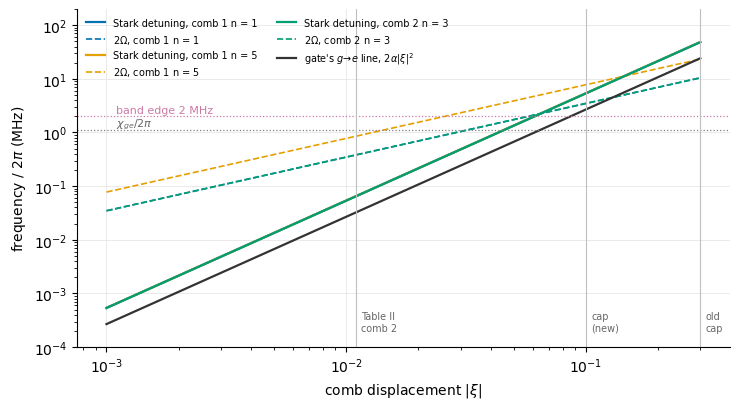

comb 1, n = 1: Stark detuning exceeds 2 Omega above |xi| = 0.064
comb 1, n = 5: Stark detuning exceeds 2 Omega above |xi| = 0.144
comb 2, n = 3: Stark detuning exceeds 2 Omega above |xi| = 0.065
gate's g->e Stark shift: 27 kHz at |xi| = 0.01, 242 kHz at 0.03, 2.69 MHz at 0.1


In [5]:
xs = np.logspace(-3, np.log10(0.3), 200)
S_ = fw12.S_diag
n_c12 = 12
fig, ax = plt.subplots(figsize=(7.5, 4.2))
cross = {}
for (c, n), col in zip([(1, 1), (1, 5), (2, 3)], OKABE):
    k = fwm.TONES.index((c, n))
    if c == 1:
        dS = S_[index(n, F, 0, n_c12)] - S_[index(n - 1, G, 0, n_c12)]
    else:
        dS = S_[index(n, G, 1, n_c12)] - S_[index(n, F, 0, n_c12)]
    det = mhz(abs(dS)) * xs ** 2
    rabi2 = 2 * mhz(fwm.tone_rate(k, 1.0)) * xs
    ax.loglog(xs, det, color=col, lw=1.6, label=f"Stark detuning, comb {c} n = {n}")
    ax.loglog(xs, rabi2, color=col, lw=1.2, ls="--", label=fr"$2\Omega$, comb {c} n = {n}")
    cross[f"comb {c}, n = {n}"] = 2 * fwm.tone_rate(k, 1.0) / abs(dS)
ax.loglog(xs, mhz(2 * dev.alpha_q) * xs ** 2, color="0.2", lw=1.6, label=r"gate's $g\to e$ line, $2\alpha|\xi|^2$")
ax.axhline(mhz(dev.chi_ge), color="0.5", lw=0.9, ls=":")
ax.text(1.1e-3, mhz(dev.chi_ge) * 1.15, r"$\chi_{ge}/2\pi$", fontsize=8, color="0.4")
ax.axhline(2.0, color=OKABE[3], lw=0.9, ls=":")
ax.text(1.1e-3, 2.3, "band edge 2 MHz", fontsize=8, color=OKABE[3])
for xv, lab in ((0.011, "Table II\ncomb 2"), (fwm.BETA_CAP, "cap\n(new)"), (0.3, "old\ncap")):
    ax.axvline(xv, color="0.75", lw=0.8)
    ax.text(xv * 1.05, 2e-4, lab, fontsize=7, color="0.4")
ax.set_ylim(1e-4, 200)
ax.set_xlabel(r"comb displacement $|\xi|$")
ax.set_ylabel("frequency / $2\\pi$ (MHz)")
ax.legend(fontsize=7, frameon=False, loc="upper left", ncol=2)
tidy(ax)
fig.tight_layout()
fig.savefig("figures/fwm_grape_stark_limit.png", dpi=150)
plt.show()
for k, v in cross.items():
    print(f"{k}: Stark detuning exceeds 2 Omega above |xi| = {v:.3f}")
print(f"gate's g->e Stark shift: {1e3 * mhz(2 * dev.alpha_q) * 0.01**2:.0f} kHz at |xi| = 0.01, "
      f"{1e3 * mhz(2 * dev.alpha_q) * 0.03**2:.0f} kHz at 0.03, {mhz(2 * dev.alpha_q) * 0.1**2:.2f} MHz at 0.1")

**Figure 1. The Stark limit.** Solid lines: Stark detuning (∝ $|\xi|^2$). Dashed lines: $2\Omega$ (∝ $|\xi|$). A
tone with a fixed carrier is useful only to the left of the crossing.

- **A fixed-carrier tone falls off resonance above $|\xi| \approx 0.06$–$0.1$** (printed above). At the old cap of
  0.3, the line has moved by about 48 MHz while the swap rate is 5–12 MHz. The tone then barely moves population.
- **A phase ramp cannot rescue it.** Retuning a tone by a phase ramp of $\beta_k(t)$ is limited to the envelope band.
  The band can be at most half the 4.14 MHz tone spacing (2 MHz) before a tone starts to imitate its neighbour. The
  Stark shift reaches 2 MHz at $|\xi| \approx 0.06$.
- **A frozen gate tolerates much less.** The gate's $g \to e$ line moves by 27 kHz at $|\xi| = 0.01$, 0.24 MHz at
  0.03 and 2.7 MHz at 0.1, against $\chi_{ge}/2\pi$ = 1.12 MHz. Any tone strong enough to swap within the gate
  detunes d2 by a large fraction of $\chi_{ge}$. This is the main prediction for Stage 2 (§6.2).

**Decision (this revision).** Cap each tone and each comb at **0.1**: the largest value where the fixed carrier is
still roughly on resonance, and where the fourth-order model is safer (transmon Stark shift $0.02\alpha$ instead of
$0.18\alpha$). Band **±2 MHz** on each envelope, half the tone spacing. The old ±1 MHz was described as "half the tone
spacing" but is a quarter of it. A **Stark-compensated carrier** (the tone frequency following $|\xi(t)|^2$) is the
way to use stronger tones. It is listed for Stage 3 (§10).

## 2.6 The full model

$$
\hat H(t) = \hat H_d + \hat H_{\rm lin}(t) + \hat H_{\rm FWM}(t) + \hat H_S(t)\;[+\,\hat H_{\rm mix}(t)],
\qquad
\frac{d\hat\rho}{dt} = -i\big[\hat H(t), \hat\rho\big] + \sum_\mu \mathcal D[\hat L_\mu]\,\hat\rho .
$$

- **Jump operators:** the DGRAPE decay set for training ($\sqrt{\kappa_a}\,\hat a$, $\sqrt{\kappa_r}\,\hat r$, and the
  two transmon decays), as in `dissipation_grape.ipynb` §4. Dephasing and heating are used for scoring only.
- **The readout is no longer inert.** Comb 2 puts photons into it, so $n_r = 2$ ($m = 0, 1$) is needed. That is enough
  for one repair at a time; $n_r = 3$ is held out. With strong constant tones ($|\beta| = 0.05$ on all six, under a
  random drive), $n_r = 2$ and 3 differ by $2\times10^{-5}$ in $F$, so the check is not empty.
- $\hat H_{\rm mix}$ is the pump-mixing term of §2.8 (opt-in; off in training, on in held-out scoring).

## 2.7 What the model leaves out

| effect | why it matters | what is done |
|---|---|---|
| **Mixing between pumps** ($\hat a^\dagger\hat r^\dagger$) | A comb-1 plus a comb-2 pump photon of the same path add up to exactly $\omega_a + \omega_r$ | Estimated and implemented (§2.8); held-out scoring with it on |
| **Pumps mixing with the linear transmon drive** | The linear drive sits near $\omega_q$; a pump photon minus a drive photon can land near other mode sums | Not modelled; an open caveat. It matters most in Stage 3, where both are strong at the same time |
| Leakage to transmon level $j = 4$ | The pump raises the transmon by two levels, so it links $\lvert f\rangle$ to $j = 4$, $4\alpha$ off resonance. The model keeps only g, e, f | `fwm_tuning` §8 estimate; small at $\lvert\xi\rvert \le 0.1$ |
| Validity of the expansion | Transmon Stark shift $2\lvert\xi\rvert^2\alpha$: 0.02 $\alpha$ at the cap | Cap 0.1 on tones and combs (§3); Stark-off stress test (§6) |
| Coupling convention | Eq. (C9) vs direct counting: a factor $\sqrt2$ | Held-out scoring with $g_c/\sqrt2$ (§6) |
| Pump-induced heating | Measured by Shirol (App. D) | Held-out scoring with all channels (§6) |

## 2.8 The pump-mixing term

In the quartic term $-\tfrac{E_J}{24}\hat\varphi^4$ with
$\hat\varphi = \varphi_q(\hat q + \hat q^\dagger + \Xi + \Xi^*) + \varphi_a(\hat a + \hat a^\dagger) + \varphi_r(\hat r + \hat r^\dagger)$,
choose one $\hat a^\dagger$, one $\hat r^\dagger$ and the two pump factors $\xi_1$, $\xi_2$. There are $4! = 24$ ways,
so the coefficient is $E_J\varphi_a\varphi_r\varphi_q^2\,\xi_1\xi_2 = \sqrt{\chi_{qa}\chi_{qr}}\,\xi_1\xi_2$ (using
$\chi_{qa} = E_J\varphi_q^2\varphi_a^2$). It carries the same sign as the comb terms, so

$$
\hat H_{\rm mix} = -\,s\,\sqrt{\chi_{ge}\chi_{qr}}\;\xi_1(t)\xi_2(t)\,\hat a^\dagger\hat r^\dagger + {\rm h.c.},
$$

with $s = 1$ if $\beta$ is the true pump displacement and $s = 2$ if it is $\sqrt2$ smaller (§2.3). For the same path,
$\xi_1\xi_2$ does not rotate in this frame. The term creates a storage photon and a readout photon *together* (a
two-mode squeeze). It moves population out of the code, and only comb 1 and comb 2 acting **at the same time**
drive it.

In [6]:
g_ar = mhz(fwm.G_MIX) * 0.1 * 0.1
theta = TWO_PI * g_ar * N_D2 * DT
print(f"g_ar/2pi at |xi_1| = |xi_2| = 0.1 (s = 1): {1e3 * g_ar:.1f} kHz; over the 1.1 us gate the pair-creation "
      f"probability from vacuum is sinh^2(g T) = {np.sinh(theta)**2:.4f} (x4 for s = 2)")
scan_path = "tables/fwm_stage2_scan.csv"
if os.path.exists(scan_path):
    sc = pd.read_csv(scan_path)
    print("measured on the scan's starts (§6.3), F with the term on (s = 1) minus off: "
          f"largest |change| {np.abs(sc.F_pro_mix1 - sc.F_pro).max():.1e}")

g_ar/2pi at |xi_1| = |xi_2| = 0.1 (s = 1): 11.2 kHz; over the 1.1 us gate the pair-creation probability from vacuum is sinh^2(g T) = 0.0061 (x4 for s = 2)
measured on the scan's starts (§6.3), F with the term on (s = 1) minus off: largest |change| 8.7e-05


**Reading.** At the cap, with both combs fully on at the same time, the term could create pairs with probability
about 0.6 % over a whole gate. In practice it is far smaller. Repair-like pulses run comb 1 and comb 2 one after the
other, and even with all tones on together the measured change in $F$ is at most $10^{-4}$ (§6.3). It is therefore
left out of training, and every trained pulse is rescored with $s = 1$ and $s = 2$.

# 3. Controls and constraints

**Table 4.** The optimizer variables. Both kinds live on the same 2 ns grid; $N = 550$ steps for a 1.1 μs gate.

| control | shape | physical meaning | hard limit | soft limit (penalty) | filtering |
|---|---|---|---|---|---|
| $u$ | $(N, 4)$ | cavity and transmon drive quadratures | box $\lvert x\rvert \le 25$ rad/μs on the pre-image | modulus $\lvert\epsilon\rvert \le 25$ rad/μs; derivative | bands ±27 / ±33 MHz, 48 ns ramp |
| $\beta$ | $(N, 12)$ | 6 tones × $(\beta^I, \beta^Q)$, pump displacement | box $\lvert\beta^{I,Q}\rvert \le 0.1$ on the pre-image | modulus $\lvert\beta_k\rvert \le 0.1$ per tone; **comb** $\lvert\xi_c(t)\rvert \le 0.1$; derivative | band **±2 MHz** on each envelope, 48 ns ramp |

The $u$ row is the d2 recipe unchanged (`DGRAPE/recipe.py`). The $\beta$ row (`DGRAPE/fwm.py`, Stage 2 recipe) works
as follows.

- **Per-tone cap, $|\beta_k| \le 0.1$.** The L-BFGS-B box acts on each quadrature separately, as for $u$, so on its
  own it allows $|\beta_k|$ up to $0.1\sqrt2$. A modulus penalty, $\sum_{t,k}(|\beta_k(t)| - 0.1)_+^2$, enforces the
  cap on $|\beta_k|$ itself. This mirrors `amp_norm="modulus"` for $u$.
- **Comb penalty, $|\xi_c(t)| \le 0.1$.** $\xi_c$ beats within a control step, so the penalty is evaluated at the
  integrator's node times (§4) and averaged per step. The Stark shift depends on $|\xi|^2$, so this is the limit that
  matters physically (§2.5).
- **Band ±2 MHz on each envelope.** `core.ramp.make_constraint_chain` is fixed at $(N, 4)$ with two bands, so
  `fwm.BetaChain` uses it three times, once per block of two tones, with both bands $(-2, 2)$ MHz and the same 48 ns
  ramp. The bands are symmetric, so the $I \mp iQ$ sign convention does not matter.
- **The tone controls are low-dimensional.** The frequency grid of a 1.1 μs pulse has a spacing of $1/T$ = 0.91 MHz.
  So a ±2 MHz band keeps 5 frequency bins per tone: 6 tones × 5 bins × 2 = **60 real degrees of freedom**, not the
  6600 entries of $x_\beta$ (the old ±1 MHz kept 3 bins). Shapes are limited to features of about 0.25 μs or longer.
- **Scaling.** L-BFGS-B is not scale-invariant, so the optimizer sees $x_\beta = s_\beta\beta$ with
  $s_\beta = 25/0.1 = 250$, and both kinds of variable share the box $|x| \le 25$. Every $\beta$ penalty weight then
  follows from the $u$ recipe as $\lambda_\beta = \lambda_u s_\beta^2$ (Table 8). These are starting values, not
  tuned ones.

In [7]:
for band in ((-1.0, 1.0), fwm.BETA_BAND):
    print(f"band {band} MHz keeps {make_band_mask(N_D2, DT, *band).sum()} frequency bins per tone")
print("beta penalty weights (Stage 2):", {k: round(v, 4) for k, v in fwm.BETA_PENALTIES.items()},
      f" s_beta = {fwm.S_BETA:.0f}")

band (-1.0, 1.0) MHz keeps 3 frequency bins per tone
band (-2.0, 2.0) MHz keeps 5 frequency bins per tone
beta penalty weights (Stage 2): {'deriv': 0.625, 'amp': 5.0, 'comb': 5.0, 'forbid': 0.0, 'transmon': 0.0}  s_beta = 250


# 4. Sub-time-steps for the FWM terms

## 4.1 The problem

DGRAPE's step (`DGRAPE.lindblad_np.step`) assumes the generator is **constant over each 2 ns step**. That is exact for
the linear drives, which are piecewise constant by construction. The FWM terms are not: each carries
$e^{i\Delta_k t}$, and Table 3 shows that phase turns by 1.7–1.8 rad within one step. Holding it constant over the
step would be wrong.

**No choice of frame removes it.** The 134 MHz comes from the transmon anharmonicity. One can move to a frame in which
$|f\rangle$ rotates at its true frequency (AQEC's frame (ii)). Then the FWM terms are slow, but the transmon drive's
$e \to f$ matrix element picks up $e^{-i\alpha t}$ instead. The fast phase is real physics: both kinds of drive touch
$|f\rangle$, one directly and one through the pumps. Dropping the $e \to f$ element (a rotating-wave approximation)
would remove the Stark shift the linear transmon drive puts on $|e\rangle$, about 0.2 MHz at full drive, so it would
change the physics.

## 4.2 The scheme

The controls ($u_k$, $\beta_k$) stay piecewise constant on the 2 ns grid. Only the time *inside* a step is refined.
Step $k$ is cut into $S$ sub-steps of length $\delta t = \Delta t / S$, and on each sub-step the carriers are read at
fixed sample times. Within one exponential the generator is then constant, so DGRAPE's Taylor action applies
unchanged.

**(a) Midpoint (second order).** One exponential per sub-step, with $\hat H$ evaluated at the sub-step midpoint
$\tau = t_{kj} + \delta t/2$, where $t_{kj} = (k + j/S)\,\Delta t$:

$$
\hat\rho \leftarrow e^{\delta t\,\mathcal L[\hat H(\tau)]}\,\hat\rho, \qquad \text{error} \propto S^{-2}.
$$

**(b) Commutator-free Magnus, fourth order (CF4; Blanes & Moan).** Two exponentials per sub-step, built from $\hat H$
at the two Gauss–Legendre nodes $\tau_{1,2} = t_{kj} + (\tfrac12 \mp \tfrac{\sqrt3}{6})\,\delta t$:

$$
\hat\rho \leftarrow
e^{\frac{\delta t}{2}\,\mathcal L[2a_1\hat H(\tau_1) + 2a_2\hat H(\tau_2)]}\;
e^{\frac{\delta t}{2}\,\mathcal L[2a_2\hat H(\tau_1) + 2a_1\hat H(\tau_2)]}\;\hat\rho,
\qquad a_{1,2} = \frac{3 \mp 2\sqrt3}{12},
\qquad \text{error} \propto S^{-4}.
$$

The right-hand exponential acts first. Here $\mathcal L[\hat H]\hat\rho = -i[\hat H, \hat\rho] + \sum_\mu \mathcal D[\hat L_\mu]\hat\rho$.
Since $2a_1 + 2a_2 = 1$, the drift, the linear drives and the dissipator each enter with weight 1. Only the
time-dependent FWM, Stark and mixing terms are mixed between the two nodes. $a_1 < 0$ is not a problem: the combined
generator is a legitimate approximation over the sub-step, and each exponential is applied as an exact (Taylor)
action.

**Taylor truncation.** $(s, m)$ come from `lnp.taylor_spec` at DGRAPE's tolerance ($10^{-15}$ per sub-step). The norm
bound is DGRAPE's plus the FWM, Stark and mixing terms (`fwm.norm_bound`):
$\theta = \big[\|\mathcal L_{\rm DGRAPE}\| + 4\sum_c|\xi_c|_{\max}\|g_c\hat A_c\| + 2\sum_c|\xi_c|_{\max}^2\|\hat S\|
+ 4|\xi_1|_{\max}|\xi_2|_{\max}\|\hat M\|\big]\times(\text{exponential length})$, with
$|\xi_c|_{\max} \le \sum_n \max_t|\beta_{c,n}(t)|$.

**Figure 2** (cell below) shows what is being sampled: the real part of the comb-1 carrier on the $n = 3$ path across
one 2 ns step, with the sample times of each scheme at $S = 4$.

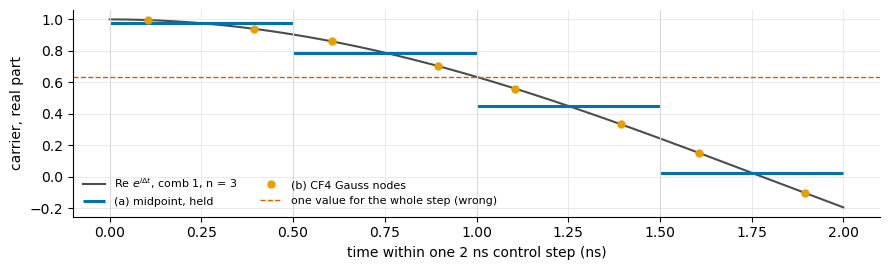

In [8]:
fig, ax = plt.subplots(figsize=(9, 2.8))
D3 = fw12.Delta[1]                                    # comb 1, n = 3
t_fine = np.linspace(0, DT, 400)
ax.plot(t_fine * 1e3, np.cos(D3 * t_fine), color="0.3", lw=1.5, label=r"Re $e^{i\Delta t}$, comb 1, n = 3")
S_demo = 4
for j in range(S_demo):
    t0, t1 = j * DT / S_demo, (j + 1) * DT / S_demo
    tm = 0.5 * (t0 + t1)
    ax.hlines(np.cos(D3 * tm), t0 * 1e3, t1 * 1e3, color=OKABE[0], lw=2.2, label="(a) midpoint, held" if j == 0 else None)
    for x in fwm.GAUSS:
        ts = t0 + x * (t1 - t0)
        ax.plot(ts * 1e3, np.cos(D3 * ts), "o", color=OKABE[1], ms=5,
                label="(b) CF4 Gauss nodes" if (j == 0 and x < 0.5) else None)
    ax.axvline(t0 * 1e3, color="0.85", lw=0.8)
ax.axhline(np.cos(D3 * DT / 2), color=OKABE[4], lw=1, ls="--", label="one value for the whole step (wrong)")
ax.set_xlabel("time within one 2 ns control step (ns)")
ax.set_ylabel("carrier, real part")
ax.legend(fontsize=8, frameon=False, loc="lower left", ncol=2)
tidy(ax)
fig.tight_layout()
fig.savefig("figures/fwm_grape_substep_sketch.png", dpi=150)
plt.show()

**Figure 2.** One 2 ns control step. Grey: the comb-1 carrier for $n = 3$, which turns by 1.77 rad over the step.
Blue: the midpoint scheme at $S = 4$ holds one value per sub-step. Orange: the CF4 scheme samples two Gauss nodes per
sub-step. Red dashed: a single value for the whole step, which is what DGRAPE's step would do if the FWM terms were
simply added.

## 4.3 The propagator (`DGRAPE/fwm.py`)

The first version of this notebook defined the propagator locally. It now lives in `DGRAPE/fwm.py`, with the exact
gradient (§4.6) and the Stage 2 objective. Nothing else in `DGRAPE/` was changed.

| name | what it is |
|---|---|
| `fwm_terms(model, mixing, g_scale)` | operators $g_c\hat A_c$, the Stark diagonal $\hat S$, the mixing operator, carriers $\Delta_k$ |
| `xi`, `h_eff` | comb displacements at time $t$; $\hat H_{\rm eff}$ at time $t$ |
| `propagate(model, fw, u, beta, dt, S, R0, scheme, stark, store)` | propagates a stack of density matrices; CF4 (default) or midpoint |
| `fidelity_and_grad(...)` | exact $F$ and $\partial F/\partial\beta$ (and $\partial F/\partial u$), W form, one W per exponential; optional occupation costate |
| `directional_derivative(...)` | the same derivative by the augmented generator: the independent reference |
| `readout_traced(T, n_c, n_r)` | the target $\hat T_b \otimes \mathbb 1_r$ of §5 |
| `BetaChain`, `Stage2Objective` | the constraint chain of §3 and the Stage 2 cost of §5.2 |
| `score(...)` | readout-traced $F_{\rm pro}$ under one scoring condition (truncation, $S$, channels, convention, ...) |

## 4.4 Checks

Each check compares the propagator with something it does not use itself.

1. **FWM off.** With every $\beta = 0$, cutting each step into sub-steps must not change anything: the d2 pulse must
   score exactly what `lnp.fidelity` gives. The same cell checks the readout-traced target of §5: with nothing driving
   the readout, it must give the same number.
2. **Convergence against an independent solver.** Tones at the old cap's scale ($|\beta_k| = 0.1$ on all six,
   random fixed phases, so $|\xi_c|$ up to 0.3, three times the new comb cap) on top of the first 0.1 μs of d2, at
   $n_c = 10$. Reference: `scipy.integrate.solve_ivp` (DOP853, `rtol` $10^{-11}$) on the Lindblad equation of §2.6
   with the exact carriers, integrated step by step.
3. **One tone against its closed form.** Closed system, linear drives off, one comb-1 tone on $n = 3$ at
   $\beta = 0.01$, start $|2,g,0\rangle$. By `fwm_tuning` §3.4 this is exactly a two-level problem:
   $P_{3f0}(t) = (4\Omega_1^2/\Omega_R^2)\sin^2(\Omega_R t/2)$ with $\Omega_R = \sqrt{4\Omega_1^2 + \delta_S^2}$,
   $\Omega_1 = g_1\beta\sqrt6$ and $\delta_S$ the Stark detuning. Run over one period (832 steps, 1.7 μs), much longer
   than check 2, so it tests the slow build-up of phase errors.
4. **The training $S$ on the whole gate.** d2 with tones at the cap, $S$ = 1, 2, 4, 8 at $n_c = 12$: how large the
   sub-step error is on the quantity actually trained, $F_{\rm pro}$ at $T_g$.
5. **The gradient** (§4.6): W form against the augmented generator and central differences.

In [9]:
m12 = Model(12, include_higher_order=True)
E12, T12, W12 = process_targets("X", 12)
T12r = fwm.readout_traced(T12, 12)

t0 = time.time()
F_lnp = lnp.fidelity(m12, U_D2, E12, T12, W12, DT)
t_lnp = time.time() - t0
t0 = time.time()
R_off, spec_off = fwm.propagate(m12, fw12, U_D2, np.zeros((N_D2, 6)), DT, 4, E12)
t_off = time.time() - t0
F_sub = process_fidelity_from_outputs(R_off, T12, W12)
F_sub_traced = process_fidelity_from_outputs(R_off, T12r, W12)
print(f"lnp.fidelity (one exponential per step)    F = {F_lnp:.12f}   [{t_lnp:.1f} s]")
print(f"fwm.propagate, CF4, S = 4, FWM off           F = {F_sub:.12f}   [{t_off:.1f} s]  |diff| = {abs(F_sub - F_lnp):.1e}")
print(f"same, readout-traced target                  F = {F_sub_traced:.12f}   |diff| = {abs(F_sub_traced - F_lnp):.1e}")
assert abs(F_sub - F_lnp) < 1e-10 and abs(F_sub_traced - F_lnp) < 1e-10

lnp.fidelity (one exponential per step)    F = 0.957239867816   [8.2 s]
fwm.propagate, CF4, S = 4, FWM off           F = 0.957239867816   [25.4 s]  |diff| = 6.7e-16
same, readout-traced target                  F = 0.957239867816   |diff| = 6.7e-16


reference: 8.3 s


observed order: midpoint 2.00 (expect 2), CF4 4.00 (expect 4)


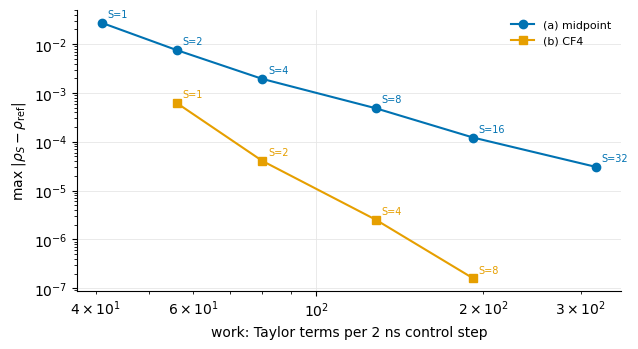

In [10]:
# Check 2: convergence in S against solve_ivp, strong tones on the first 0.1 us of d2, n_c = 10
m10 = Model(10, include_higher_order=True)
fw10 = fwm.fwm_terms(m10)
E10, _, _ = process_targets("X", 10)
N_CHK = 50
u_chk = U_D2[:N_CHK]
rng = np.random.default_rng(0)
beta_chk = np.tile(0.1 * np.exp(2j * np.pi * rng.random(6)), (N_CHK, 1))
c_ops10 = [c for _, c in m10.c_ops]
cdc10 = sum(c.conj().T @ c for c in c_ops10)


def rhs_reference(t, y, k):
    # Lindblad equation of §2.6 with the exact carriers (no sub-steps), step k's controls held
    R = y.reshape(-1, m10.d, m10.d)
    H = fwm.h_eff(m10, fw10, m10.H_d + np.tensordot(u_chk[k], m10.Hc, axes=1), beta_chk[k], t)
    out = -1j * (H @ R - R @ H) - 0.5 * (cdc10 @ R + R @ cdc10)
    for c in c_ops10:
        out += c @ R @ c.conj().T
    return out.ravel()


t0 = time.time()
R_ref = E10.astype(complex)
for k in range(N_CHK):
    R_ref = solve_ivp(rhs_reference, (k * DT, (k + 1) * DT), R_ref.ravel(), args=(k,), method="DOP853",
                      rtol=1e-11, atol=1e-13).y[:, -1].reshape(R_ref.shape)
print(f"reference: {time.time() - t0:.1f} s")

conv = []
for S in (1, 2, 4, 8, 16, 32):
    for scheme in ("midpoint", "cf4"):
        if scheme == "cf4" and S > 8:
            continue
        R_S, (s_, m_) = fwm.propagate(m10, fw10, u_chk, beta_chk, DT, S, E10, scheme=scheme)
        conv.append({"scheme": scheme, "S": S, "max |rho_S - rho_ref|": np.abs(R_S - R_ref).max(),
                     "Taylor terms per 2 ns step": S * (2 if scheme == "cf4" else 1) * s_ * m_})
conv = pd.DataFrame(conv)
display(conv.pivot(index="S", columns="scheme").style.format("{:.3g}")
        .set_caption("Table 5. Sub-step convergence against solve_ivp: error after 0.1 us of d2 with strong tones "
                     "(|beta_k| = 0.1 on all six), n_c = 10, and the work per control step."))
err = conv.set_index(["scheme", "S"])["max |rho_S - rho_ref|"]
order_mid = np.log2(err["midpoint"][8] / err["midpoint"][16])
order_cf4 = np.log2(err["cf4"][4] / err["cf4"][8])
print(f"observed order: midpoint {order_mid:.2f} (expect 2), CF4 {order_cf4:.2f} (expect 4)")
assert 1.8 < order_mid < 2.2 and 3.6 < order_cf4 < 4.4
assert err["cf4"][4] < 1e-5

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for scheme, col, mk in (("midpoint", OKABE[0], "o"), ("cf4", OKABE[1], "s")):
    sub = conv[conv.scheme == scheme]
    ax.loglog(sub["Taylor terms per 2 ns step"], sub["max |rho_S - rho_ref|"], marker=mk, color=col, lw=1.5,
              label={"midpoint": "(a) midpoint", "cf4": "(b) CF4"}[scheme])
    for _, r in sub.iterrows():
        ax.annotate(f"S={int(r.S)}", (r["Taylor terms per 2 ns step"], r["max |rho_S - rho_ref|"]),
                    textcoords="offset points", xytext=(4, 4), fontsize=7, color=col)
ax.set_xlabel("work: Taylor terms per 2 ns control step")
ax.set_ylabel(r"max $|\rho_S - \rho_{\rm ref}|$")
ax.legend(frameon=False, fontsize=8)
tidy(ax)
fig.tight_layout()
fig.savefig("figures/fwm_grape_substep_convergence.png", dpi=150)
plt.show()

**Table 5 and Figure 3.** Error against work for both schemes. Each point is one $S$. The x axis counts Taylor terms
per control step, which is what the run time scales with.

- **Both schemes converge at their expected order.** The midpoint error falls 4× per doubling of $S$, the CF4 error
  16×.
- **CF4 wins clearly.** At $S = 4$ it is about 50 times more accurate than the midpoint scheme at $S = 16$, for two
  thirds of the work. Its Taylor series are also shorter, because each exponential covers only half a sub-step.
- **One value per step ($S = 1$, midpoint) is off by a few percent** in $\hat\rho$ after only 0.1 μs. Adding the FWM
  terms to DGRAPE's step without sub-steps would not work.

In [11]:
# Check 3: one comb-1 tone, n = 3, closed system, against the two-level closed form
m8c = Model(8, include_higher_order=True, rate_scale=0.0)
fw8 = fwm.fwm_terms(m8c)
b_one = 0.01
O1 = fwm.G1 * b_one * np.sqrt(6)
i0, i1 = index(2, G, 0, 8), index(3, F, 0, 8)
dS = -b_one ** 2 * (fw8.S_diag[i1] - fw8.S_diag[i0])          # Stark detuning of the pair
OR = np.hypot(2 * O1, dS)
N_one = int(round(np.pi / O1 / DT))
beta_one = np.zeros((N_one, 6), dtype=complex)
beta_one[:, 1] = b_one                                          # tone (comb 1, n = 3)
psi0 = np.zeros(m8c.d)
psi0[i0] = 1.0
t_one = np.arange(N_one) * DT                                   # store=True keeps the state at the start of each step
P_closed_form = 4 * O1 ** 2 / OR ** 2 * np.sin(OR * t_one / 2) ** 2
rows = []
for S in (2, 4, 8, 16):
    _, hist = fwm.propagate(m8c, fw8, np.zeros((N_one, 4)), beta_one, DT, S, np.outer(psi0, psi0)[None], store=True)
    P = np.array([np.real(h[0, i1, i1]) for h in hist])
    rows.append({"S (CF4)": S, "max |P_3f0 - closed form|": np.abs(P - P_closed_form).max(), "largest P_3f0": P.max()})
one_tone = pd.DataFrame(rows)
display(one_tone.style.hide(axis="index").format({"max |P_3f0 - closed form|": "{:.2e}", "largest P_3f0": "{:.6f}"})
        .set_caption(f"Table 6. One comb-1 tone (n = 3, beta = {b_one}), closed system, {N_one} steps "
                     f"= {N_one * DT:.2f} us, against the closed form of fwm_tuning §3.4."))
print(f"Omega_1/2pi = {1e3 * mhz(O1):.1f} kHz, Stark detuning/2pi = {1e3 * mhz(dS):.2f} kHz, "
      f"closed-form contrast {4 * O1**2 / OR**2:.6f}")
assert one_tone.set_index("S (CF4)").loc[8, "max |P_3f0 - closed form|"] < 1e-5

S (CF4),max |P_3f0 - closed form|,largest P_3f0
2,4.91e-04,0.992031
4,3.10e-05,0.992034
8,1.94e-06,0.992035
16,1.21e-07,0.992035


Omega_1/2pi = 300.4 kHz, Stark detuning/2pi = -53.82 kHz, closed-form contrast 0.992038


**Reading Table 6.**

- **The coupling, the carrier and the Stark shift are right.** The largest $P_{3f0}$ matches the closed-form contrast
  $1/(1 + (8.96\beta)^2)$ of `fwm_tuning` §4, and the error falls 16× per doubling of $S$.
- **The Stark detuning, −53.8 kHz at $\beta = 0.01$, is the $2\pi\cdot 538\ {\rm MHz}\cdot|\xi|^2$ of §2.5.**
- **Errors build up over long runs.** At $S = 4$ the error is $3\times10^{-5}$ after 1.7 μs, larger than check 2's
  short window suggests. It is a phase error that accumulates step by step. Check 4 measures it on the quantity that
  is trained.

In [12]:
# Check 4: S on the whole d2 gate with tones at the cap, n_c = 12 (forward only)
rng = np.random.default_rng(0)
cases = {"six tones, |beta| = 0.033 each, random phases (|xi_c| <= 0.1)":
             np.tile(fwm.BETA_CAP / 3 * np.exp(2j * np.pi * rng.random(6)), (N_D2, 1)),
         "one tone per comb at 0.1 (n = 3)": np.tile(np.array([0, 0.1, 0, 0, 0.1, 0], complex), (N_D2, 1)),
         "six tones at 0.1 (box worst case)": np.tile(0.1 * np.exp(2j * np.pi * rng.random(6)), (N_D2, 1))}
rows = []
for name, b in cases.items():
    Fs = {S: fwm.fidelity(m12, fw12, U_D2, b, E12, T12r, W12, DT, S) for S in (1, 2, 4, 8)}
    rows.append({"tones (constant, whole gate)": name, **{f"F (S={S})": v for S, v in Fs.items()},
                 "F(2) - F(8)": Fs[2] - Fs[8], "F(4) - F(8)": Fs[4] - Fs[8]})
s_choice = pd.DataFrame(rows)
display(s_choice.style.hide(axis="index")
        .format({c: "{:.6f}" for c in s_choice.columns if c.startswith("F (")} | {"F(2) - F(8)": "{:+.1e}", "F(4) - F(8)": "{:+.1e}"})
        .set_caption("Table 6b. Sub-step error on F_pro at the end of the d2 gate, n_c = 12, CF4."))
assert s_choice["F(2) - F(8)"].abs().max() < 1e-4

"tones (constant, whole gate)",F (S=1),F (S=2),F (S=4),F (S=8),F(2) - F(8),F(4) - F(8)
"six tones, |beta| = 0.033 each, random phases (|xi_c| <= 0.1)",0.066031,0.066658,0.066698,0.066701,-4.3e-05,-2.6e-06
one tone per comb at 0.1 (n = 3),0.012877,0.013034,0.013045,0.013046,-1.1e-05,-6.7e-07
six tones at 0.1 (box worst case),0.023134,0.023035,0.023028,0.023027,+7.3e-06,+4.4e-07


**Reading Table 6b and the choice of $S$.**

- **At the cap, $S = 2$ is within $5\times10^{-5}$ of $S = 8$ in $F_{\rm pro}$, and $S = 4$ within $3\times10^{-6}$.**
  Check 2 used $|\xi_c|$ up to 0.3; at the new comb cap of 0.1 the time-dependent terms are three times smaller,
  so fewer sub-steps suffice.
- **Constant tones at the cap wreck the frozen gate**: $F_{\rm pro}$ falls from 0.957 to 0.01–0.07. That is the
  Stark shift of §2.5 acting on d2's transmon line, and it anticipates §6.

**Choice.** Train with **CF4 at $S = 2$** (about 35 % cheaper than $S = 4$) and rescore every trained pulse at
**$S = 4$ and $S = 8$**: "held-out $S$", in the same spirit as DGRAPE's held-out truncations. If the scores differ
by more than about $10^{-4}$, raise $S$.

## 4.5 Cost of one evaluation

The run time of a Taylor propagator scales with the number of terms applied per control step:
$S \times$ (exponentials per sub-step) $\times\, s \times m$. Table 7 compares that with DGRAPE's current step on the
d2 pulse at the training truncation $n_c = 16$. It covers tones at the comb cap $|\xi_c| = 0.1$ and the worst case
the box allows ($|\beta_k| = 0.1\sqrt2$ on all three tones of a comb). Measured times come from the Stage 2 runs.

In [13]:
m16 = Model(16, include_higher_order=True)
fw16 = fwm.fwm_terms(m16)
s_now, m_now = lnp.spec_for_pulse(m16, U_D2, DT)
rows = [{"scheme": "DGRAPE today (no tones)", "S": 1, "|xi_c| max": 0.0, "(s, m) per exponential": f"({s_now}, {m_now})",
         "terms per step": s_now * m_now, "work vs today": 1.0}]
for xmax in (fwm.BETA_CAP, 3 * fwm.BETA_CAP * np.sqrt(2)):
    for scheme, S in (("cf4", 2), ("cf4", 4), ("cf4", 8)):
        beta_w = np.zeros((N_D2, 6), complex)
        beta_w[:, 0], beta_w[:, 3] = xmax, xmax            # one tone per comb carries the whole |xi_c|
        s_, m_ = fwm.spec_for(m16, fw16, U_D2, beta_w, DT, S, scheme)
        terms = S * 2 * s_ * m_
        rows.append({"scheme": scheme, "S": S, "|xi_c| max": xmax, "(s, m) per exponential": f"({s_}, {m_})",
                     "terms per step": terms, "work vs today": terms / (s_now * m_now)})
display(pd.DataFrame(rows).style.hide(axis="index").format({"|xi_c| max": "{:.2f}", "work vs today": "{:.1f}"})
        .set_caption("Table 7. Taylor work per 2 ns control step at n_c = 16 (d2 drives), today and with tones."))
runs_json = sorted(glob.glob("pulses/dgrape/X_fwm_s2_*.json"))
if runs_json:
    per_eval = [json.load(open(p))["wall_s"] / max(json.load(open(p))["n_evals"], 1) for p in runs_json]
    print(f"measured Stage 2 cost (n_c = 16, CF4 S = 2, F + exact gradient, 3 parallel jobs, 4 runs sharing an "
          f"i7-13700KF): {np.mean(per_eval):.0f} s per evaluation (range {min(per_eval):.0f}-{max(per_eval):.0f} s)")

scheme,S,|xi_c| max,"(s, m) per exponential",terms per step,work vs today
DGRAPE today (no tones),1,0.00,"(1, 28)",28,1.0
cf4,2,0.10,"(1, 17)",68,2.4
cf4,4,0.10,"(1, 13)",104,3.7
cf4,8,0.10,"(1, 11)",176,6.3
cf4,2,0.42,"(1, 25)",100,3.6
cf4,4,0.42,"(1, 19)",152,5.4
cf4,8,0.42,"(1, 15)",240,8.6


measured Stage 2 cost (n_c = 16, CF4 S = 2, F + exact gradient, 3 parallel jobs, 4 runs sharing an i7-13700KF): 74 s per evaluation (range 74-74 s)


**Reading Table 7.** CF4 at $S = 2$ costs about 2.5× DGRAPE's step at the cap, $S = 4$ about 4×. The exact gradient
costs about 4.4 forward passes. One pass recomputes each step from the stored state at its start, one runs the
costate backward, and two GEMMs build W. Storing every sub-step state instead would need about 6 GB at $n_c = 16$.
The box worst case costs about twice the cap case, because the Taylor series lengthen with the generator norm. The
comb penalty keeps the pulse near the first rows as well as keeping the model valid.

## 4.6 The exact gradient

DGRAPE's gradient (`lnp.fidelity_and_grad`) uses one matrix $W_k$ per step such that, for anything $\theta$ that
enters the step's Hamiltonian, $\partial F/\partial\theta = \mathrm{Re}\,\mathrm{Tr}\big[(\partial\hat H_k/\partial\theta)\,W_k\big]$.
That identity needs only that the generator is affine in $\hat H$, which holds here. It carries over with **one W per
exponential**, $W_{kje}$ (step $k$, sub-step $j$, exponential $e$). Each $W_{kje}$ is computed from the forward terms
of that exponential and the backward costates, exactly as now. Let $w_{e1}, w_{e2}$ be the exponential's node weights
($2a_2, 2a_1$ for the first, $2a_1, 2a_2$ for the second). Its Hamiltonian is linear in three node sums:
$\zeta_{ec} = \sum_\nu w_{e\nu}\xi_c(\tau_\nu)$, $\sigma_e = \sum_\nu w_{e\nu}\sum_c|\xi_c(\tau_\nu)|^2$ and
$\mu_e = \sum_\nu w_{e\nu}\xi_1\xi_2(\tau_\nu)$:

- **Linear drives** (weight 1 in every exponential):
  $\displaystyle \frac{\partial F}{\partial u_{kq}} = \sum_{j,e}\mathrm{Re}\,\mathrm{Tr}\big[\hat H_{c,q}W_{kje}\big]$.
- **Tones.** With $\partial\xi_c(\tau)/\partial\beta^I_{k} = e^{i\Delta_k\tau}$ for $k$ in comb $c$, and $-i$ times that
  for $\beta^Q_k$:
  $$
  \frac{\partial F}{\partial\theta} = \sum_{j,e}\mathrm{Re}\Big\{
  \frac{\partial\zeta_{ec}}{\partial\theta}\mathrm{Tr}[g_c\hat A_cW] + \frac{\partial\zeta^*_{ec}}{\partial\theta}\mathrm{Tr}[g_c\hat A_c^\dagger W]
  - \frac{\partial\sigma_e}{\partial\theta}\mathrm{Tr}[\hat S W]
  + \frac{\partial\mu_e}{\partial\theta}\mathrm{Tr}[\hat M W] + \frac{\partial\mu^*_e}{\partial\theta}\mathrm{Tr}[\hat M^\dagger W]\Big\},
  $$
  with $\partial\sigma_e/\partial\theta = \sum_\nu w_{e\nu}\,2\,\mathrm{Re}\big[\xi_c^*(\tau_\nu)\,\partial\xi_c(\tau_\nu)/\partial\theta\big]$.
- **Occupation costs** (forbidden states, transmon excitation) ride extra costate entries with a projector source at
  every step, exactly as in DGRAPE. They are off in Stage 2 training (§5.2) and reported at scoring.
- **Verification.** No JAX on this machine, so the second exact method is the augmented generator
  ($\dot x = \mathcal L x$, $\dot y = \mathcal L y - i[\delta\hat H, x]$) run through the same Taylor polynomial
  (`fwm.directional_derivative`), plus central differences. `validation/test_fwm_grape.py` checks both, with and
  without the mixing term, for CF4 and midpoint, and for the occupation costate. The cell shows one case.

In [14]:
rng = np.random.default_rng(1)
m7 = Model(7, include_higher_order=True)
fw7 = fwm.fwm_terms(m7, mixing=1.0)
E7, T7, W7 = process_targets("X", 7)
T7 = fwm.readout_traced(T7, 7)
u7 = rng.normal(0, 8, (12, 4))
b7 = 0.05 * (rng.normal(size=(12, 6)) + 1j * rng.normal(size=(12, 6)))
spec7 = fwm.spec_for(m7, fw7, u7, b7, DT, 2)
F7, gb7, gu7 = fwm.fidelity_and_grad(m7, fw7, u7, b7, E7, T7, W7, DT, 2, spec=spec7, want_u=True)
db = rng.normal(size=b7.shape) + 1j * rng.normal(size=b7.shape)
du = rng.normal(size=u7.shape)
w_form = np.sum(gb7 * fwm.real_from_beta(db)) + np.sum(gu7 * du)
augmented = fwm.directional_derivative(m7, fw7, u7, b7, E7, T7, W7, DT, 2, db, du, spec=spec7)
h = 1e-5
central = (fwm.fidelity(m7, fw7, u7 + h * du, b7 + h * db, E7, T7, W7, DT, 2, spec=spec7)
           - fwm.fidelity(m7, fw7, u7 - h * du, b7 - h * db, E7, T7, W7, DT, 2, spec=spec7)) / (2 * h)
print(f"directional derivative (n_c = 7, 12 steps, CF4 S = 2, mixing on):\n  W form     {w_form:.15e}\n"
      f"  augmented  {augmented:.15e}   rel diff {abs(w_form - augmented) / abs(augmented):.1e}\n"
      f"  central    {central:.15e}   rel diff {abs(w_form - central) / abs(augmented):.1e}")

directional derivative (n_c = 7, 12 steps, CF4 S = 2, mixing on):
  W form     7.683006503956913e-05
  augmented  7.683006503956899e-05   rel diff 1.8e-15
  central    7.683006876440580e-05   rel diff 4.8e-08


# 5. Cost functions

## 5.1 The fidelity, scored at the end of the gate

DGRAPE's process fidelity (`DGRAPE/code.py`) propagates the inputs $\hat E_b$ (b = 00, 11, 01: code states with the
transmon in g and the readout empty). It compares them with targets $\hat T_b$ that also carry $|g, 0\rangle$. With
FWM tones the readout photon is the *dumped error*, not a mistake, so the readout is traced out:

$$
F_{\rm pro} = \frac14\sum_b w_b\,\mathrm{Re}\,\mathrm{Tr}\Big[\big(\hat T_b\otimes\mathbb 1_r\big)^\dagger\,\Phi_T(\hat E_b)\Big]
= \frac14\sum_b w_b\,\mathrm{Re}\,\mathrm{Tr}\Big[\hat T_b^\dagger\,\mathrm{Tr}_r\,\Phi_T(\hat E_b)\Big],
\qquad w = (1, 1, 2).
$$

This is the process fidelity of the channel with the readout discarded at $T_g$, computed by `fwm.readout_traced`.
It is still linear in the channel $\Phi_T$, so the exact gradient keeps its form: the backward pass starts from
$\tfrac{w_b}{4}\hat T_b\otimes\mathbb 1_r$.

- **Scored at $t = T_g$** (the project's choice). A repair counts only if comb 2 has returned the transmon to $g$ by
  then. A readout photon still present is fine (traced out); the transmon left in $|f\rangle$ or $|e\rangle$ is not.
- **Consequence.** A loss late in the gate cannot be repaired in time, so even a perfect co-design leaves part of
  the photon-loss cost (at least the losses in the last ~0.5 μs, about 1.1 %). A fixed PReSPA tail after the
  gate would credit late repairs too; it is listed as an open decision (§10).
- **One caveat of tracing.** A readout photon left at $T_g$ needs ~0.3–1 μs to leak out before the next repair can
  use the readout. Every pulse reports $\langle\hat n_r\rangle(T_g)$.

## 5.2 Stage 2 cost (tones only, gate frozen)

$$
\begin{aligned}
C_2(\beta) =\;& 1 - F_{\rm pro}\big(u_{d2}, \beta\big) && n_c = 16,\ \text{CF4}\ S = 2\\
&+ \lambda_{a\beta}\sum_{t,k}\big(|\beta_k(t)| - 0.1\big)_+^2 && \text{per-tone cap (modulus)}\\
&+ \lambda_{\xi}\,\frac{1}{2S}\sum_{t}\sum_{c}\sum_{\text{nodes}}\big(|\xi_c(\tau)| - 0.1\big)_+^2 && \text{comb displacement}\\
&+ \lambda_{d\beta}\sum_{t,k}|\beta_k(t+\Delta t) - \beta_k(t)|^2 && \text{smoothness}
\end{aligned}
$$

with $\beta = $ ramp(band-limit($x_\beta$))$/s_\beta$ and $u_{d2}$ = `pulses/dgrape/u_X_open_d2.npy` fixed.
**The forbidden-state term is off in Stage 2.** $u$ is frozen, so d2's forbidden occupation is a constant, and the
tones add at most one photon to states with $n \le 4$, far below Fock 10. Its costate would add about 40 % per
evaluation for nothing. $C_{\rm forbid}$ is still reported for every pulse. Eq. 24 is inactive with one truncation.

## 5.3 Stage 3 cost (joint)

$$
C_3(u, \beta) = C_2(\beta)\big|_{u\ \text{free}}
+ \lambda_{\rm deriv}\sum_t|u(t+\Delta t) - u(t)|^2
+ \lambda_{\rm amp}\sum_{t,d}\big(|\epsilon_d(t)| - 25\big)_+^2
+ \lambda_{\rm forbid}\,C_{\rm forbid}
\;\big[+\,\lambda_{\rm transmon}C_T\big],
$$

i.e. the d2 recipe for $u$ plus everything of $C_2$. With $u$ free, the forbidden-state term is back on. The
gradient code already provides $\partial F/\partial u$ and the occupation costate.

**Table 8.** Weights (starting values; the $\beta$ weights are the $u$-recipe weights times $s_\beta^2 = 62\,500$, §3).

| term | weight | source |
|---|---|---|
| $\lambda_{\rm deriv}$, $\lambda_{\rm amp}$ (on $u$, Stage 3) | $10^{-5}$, $8\times10^{-5}$ | DGRAPE recipe |
| $\lambda_{d\beta}$ | 0.625 | $10^{-5}\,s_\beta^2$ |
| $\lambda_{a\beta}$, $\lambda_\xi$ | 5.0 | $8\times10^{-5}\,s_\beta^2$ |
| $\lambda_{\rm forbid}$ (storage Fock $\ge 10$) | 0 in Stage 2; $10^{-3}$ in Stage 3 | §5.2; DGRAPE recipe |
| $\lambda_{\rm transmon}$ | 0 or $10^{-4}$ (Stage 3) | §12 of the parent notebook |

**Truncations.** Train at $n_c = 16$ alone (§12 of the parent: one truncation suffices for X; comb 1 adds one photon,
still far below the forbidden threshold at 10). Hold out $n_c = 18, 20$, $n_r = 3$, and $S = 4, 8$.

# 6. Stage 2: freeze the d2 gate, optimize only the tones

**Question.** Given the d2 gate as it is, can tone shapes be found that repair some photon loss *without* disturbing
the gate? It is a cheap first test of the idea, and of the training machinery, with a known gate underneath.

## 6.1 Baselines

The cell computes these at $n_c = 12$ with CF4, $S = 4$:

- **tones off**: the d2 gate as trained (0.9572 at $n_c = 12$; 0.9556 at $n_c = 16$);
- **Shirol's Table II tones, constant, on during the whole gate**: all six, and each comb alone;
- the same six tones **with the Stark term switched off**, to separate Stark detuning from crosstalk.

In [15]:
ops12 = operators(12)
baseline_cases = [("tones off", np.zeros(6), True),
                  ("Table II, all six tones", fwm.BETA_TABLE2, True),
                  ("Table II, comb 1 only", fwm.BETA_TABLE2 * fwm.comb_mask(1), True),
                  ("Table II, comb 2 only", fwm.BETA_TABLE2 * fwm.comb_mask(2), True),
                  ("Table II, all six, Stark off", fwm.BETA_TABLE2, False)]
rows = []
for name, b6, stark in baseline_cases:
    t0 = time.time()
    R, _ = fwm.propagate(m12, fw12, U_D2, np.tile(b6.astype(complex), (N_D2, 1)), DT, 4, E12, stark=stark)
    F_ = process_fidelity_from_outputs(R, T12r, W12)
    n_r_end = np.mean([np.real(np.trace(ops12["n_r"] @ R[b])) for b in (0, 1)])
    rows.append({"case": name, "F_pro": F_, "change vs tones off": np.nan, "<n_r> at T_g": n_r_end,
                 "seconds": time.time() - t0})
baseline = pd.DataFrame(rows)
baseline["change vs tones off"] = baseline.F_pro - baseline.F_pro[0]
display(baseline.style.hide(axis="index")
        .format({"F_pro": "{:.5f}", "change vs tones off": "{:+.4f}", "<n_r> at T_g": "{:.2e}", "seconds": "{:.0f}"})
        .set_caption("Table 9. Stage 2 baselines: the d2 X gate with Shirol's Table II tones left on, n_c = 12, CF4 S = 4, "
                     "readout-traced target, decay set. <n_r> averaged over |0_L>, |1_L>."))
assert abs(baseline.F_pro[0] - F_lnp) < 1e-10

case,F_pro,change vs tones off,at T_g,seconds
tones off,0.95724,+0.0000,0.00e+00,22
"Table II, all six tones",0.93101,-0.0262,3.26e-04,25
"Table II, comb 1 only",0.94831,-0.0089,0.00e+00,25
"Table II, comb 2 only",0.94054,-0.0167,2.65e-10,25
"Table II, all six, Stark off",0.94838,-0.0089,3.51e-04,29


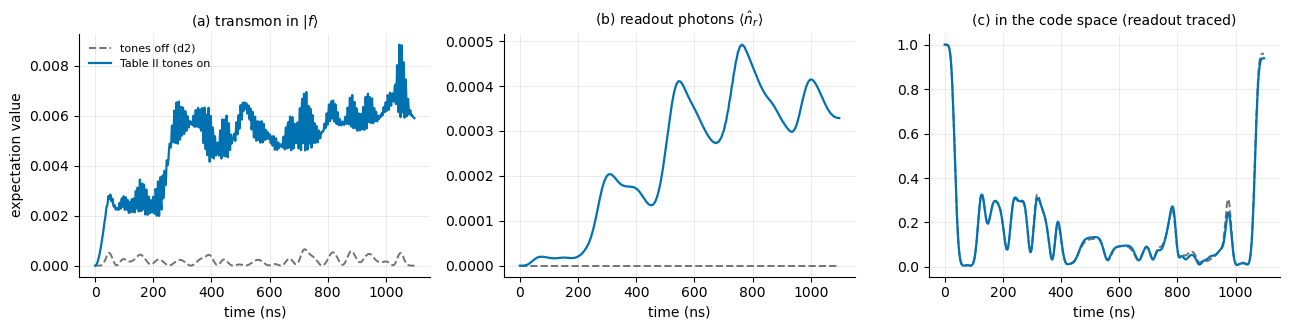

from |0_L>: max P_f 0.0089 (tones off 6.6e-04); max <n_r> 4.92e-04


In [16]:
# Where the population goes from |0_L> with and without the Table II tones (n_c = 12)
B12 = embedded_basis(12)
P_code = fwm.readout_traced((B12 @ B12.conj().T)[None], 12)[0]          # code space, any readout level
rho0 = np.outer(B12[:, 0], B12[:, 0].conj())[None]
_, h_off = fwm.propagate(m12, fw12, U_D2, np.zeros((N_D2, 6)), DT, 4, rho0, store=True)
_, h_on = fwm.propagate(m12, fw12, U_D2, np.tile(fwm.BETA_TABLE2.astype(complex), (N_D2, 1)), DT, 4, rho0, store=True)
expect = lambda op, hist: np.array([np.real(np.trace(op @ h[0])) for h in hist])     # noqa: E731
t_ns = np.arange(N_D2) * DT * 1e3
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, (op, title) in zip(axes, [(ops12["Pf"], r"(a) transmon in $|f\rangle$"),
                                  (ops12["n_r"], r"(b) readout photons $\langle\hat n_r\rangle$"),
                                  (P_code, "(c) in the code space (readout traced)")]):
    ax.plot(t_ns, expect(op, h_off), color="0.45", lw=1.4, ls="--", label="tones off (d2)")
    ax.plot(t_ns, expect(op, h_on), color=OKABE[0], lw=1.6, label="Table II tones on")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("time (ns)")
    tidy(ax)
axes[0].set_ylabel("expectation value")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig("figures/fwm_grape_tableII_trajectories.png", dpi=150)
plt.show()
print(f"from |0_L>: max P_f {expect(ops12['Pf'], h_on).max():.4f} (tones off {expect(ops12['Pf'], h_off).max():.1e}); "
      f"max <n_r> {expect(ops12['n_r'], h_on).max():.2e}")

**Table 9 and Figure 4.** The d2 gate from $|0_L\rangle$ with and without Shirol's tones: (a) population with the
transmon in $|f\rangle$, (b) readout photons, (c) population in the code space, readout traced.

- **Shirol's tones, left on, cost 2.6 %** at $n_c = 12$. Comb 2 alone costs 1.7 %, comb 1 alone 0.9 %.
- **Two thirds of that is the Stark shift.** Switching only the Stark term off leaves a cost of 0.9 %. Comb 2's tones
  are the strong ones ($\beta = 0.011$ each, three in a comb), and their Stark shift moves the transmon's $g \to e$
  line by about 0.1 MHz on average. The gate uses that line for its photon-number-selective rotations. The shift
  beats at multiples of 4.14 MHz.
- **The rest is crosstalk.** The tones move the gate's intermediate states into $|f\rangle$ (up to 0.9 %) and the
  readout (up to $5\times10^{-4}$), little by little (Fig. 4a, b); the gate was not built for that.
- **The code-space population barely changes (Fig. 4c).** So most of the 2.6 % is a wrong *phase*, not population
  leaving the code, which fits the Stark detuning being the larger cost.

(The first version of this notebook also quoted agreement with an "AQEC six-tone model, 0.949, run earlier". That
number was not computed in any notebook, so the claim is dropped.)

**What Stage 2 must beat is "tones off", not Table II.** The optimizer can always switch the tones off, so a useful
result is any $\beta(t)$ that scores *above* tones off at converged truncation.

## 6.2 Prediction, recorded before training

1. **Stark shift against swap time.** To finish a comb-2 swap in the time available, $\Omega t \approx \pi/2$ needs
   $|\beta_2| \gtrsim 0.03$ in 0.3 μs. At that strength the gate's $g \to e$ line moves by about 0.24 MHz, a fifth of
   $\chi_{ge}$, for as long as the tone is on. With $u$ frozen, nothing can correct that shift.
2. **Repairs act on scrambled error states.** A loss mid-gate is followed by the rest of a gate never trained
   on error states. A repair at $T_g$ maps "comb-1 states" back into the code, but they are not the loss of the
   *target* state.
3. **β = 0 is a local maximum.** A repair needs comb 1 *and* comb 2, so its gain is fourth order in $\beta$, while
   crosstalk costs at second order. Small tones only cost.

**So Stage 2 is expected to find little or nothing above tones off.** A null result would not falsify Stage 3: there
$u$ can absorb the Stark shift (retune its own drive) and can learn to act sensibly on error states.

## 6.3 Landscape scan

Because β = 0 is a local maximum, the optimizer must start where a repair can work. `DGRAPE/fwm_stage2_scan.py`
scored 12 candidate starts, each passed through the training chain, at the training settings ($n_c = 16$, CF4 $S = 2$):

- Table II tones, ×1, ×3, ×9, over the whole gate or the last 0.5 μs;
- **sequential repairs**: comb 1 in a window A, then comb 2 in a window B, at the amplitude that gives a full swap
  in the window (×0.5 and ×1). "short": A, B = last 0.5–0.25 μs, last 0.25 μs; "long": last 0.7–0.35 μs,
  last 0.35 μs. Plus each comb alone.

In [17]:
scan = pd.read_csv("tables/fwm_stage2_scan.csv")
cols = ["start", "F_pro", "change_vs_off", "F_pro_mix1", "max_beta", "max_xi_1", "max_xi_2", "P_f_end", "n_r_end"]
display(scan[cols].style.hide(axis="index")
        .format({"F_pro": "{:.4f}", "change_vs_off": "{:+.4f}", "F_pro_mix1": "{:.4f}", "max_beta": "{:.3f}",
                 "max_xi_1": "{:.3f}", "max_xi_2": "{:.3f}", "P_f_end": "{:.1e}", "n_r_end": "{:.1e}"})
        .set_caption("Table 10. Landscape scan: candidate starts at the training settings (n_c = 16, CF4 S = 2). "
                     "F_pro_mix1: with the pump-mixing term on (s = 1)."))

start,F_pro,change_vs_off,F_pro_mix1,max_beta,max_xi_1,max_xi_2,P_f_end,n_r_end
off,0.9556,+0.0000,0.9556,0.000,0.000,0.000,1.4e-08,0.0e+00
tableII_x1_full,0.9280,-0.0275,0.9280,0.011,0.007,0.033,6.6e-03,3.0e-04
tableII_x3_full,0.1295,-0.8261,0.1296,0.033,0.020,0.099,1.8e-02,5.8e-03
tableII_x9_full,0.0095,-0.9460,0.0096,0.099,0.060,0.297,2.9e-02,2.0e-02
tableII_x3_last0.5,0.5216,-0.4340,0.5216,0.039,0.020,0.096,8.1e-03,3.0e-03
tableII_x9_last0.5,0.0262,-0.9294,0.0262,0.116,0.059,0.289,1.2e-02,1.4e-02
seq_short_f0.5,0.7038,-0.2518,0.7038,0.028,0.056,0.083,7.2e-02,9.7e-03
seq_short_f1.0,0.1220,-0.8335,0.1220,0.055,0.112,0.165,1.1e-01,1.0e-02
seq_long_f0.5,0.8007,-0.1549,0.8007,0.024,0.040,0.067,5.2e-02,6.4e-03
seq_long_f1.0,0.1721,-0.7835,0.1721,0.047,0.080,0.135,8.7e-02,1.1e-02


**Reading Table 10.**

- **Every start scores below tones off (0.9556).** Table II left on costs 2.8 %. A sequential repair at half the
  swap amplitude costs 15 % ("long") to 25 % ("short"). At full swap amplitude only 0.12–0.17 is left.
- **Comb 2 alone in the last 0.35 μs costs 58 %, and it barely touches the gate's states** ($P_f$ at $T_g$ is
  $5\times10^{-8}$). So the damage is the Stark shift on the gate's transmon line, as §6.2 predicted, not crosstalk.
- The pump-mixing term changes $F$ by at most $10^{-4}$ here.
- **Starts chosen for the runs**: "long" ×0.5 (best sequential), "short" ×0.5, Table II over the whole gate, and
  near-zero tones (noise $2\times10^{-3}$) as the control for "is β = 0 a local maximum".

## 6.4 Protocol (as run)

1. **Variables:** $x_\beta$, $(550, 12)$; $u = u_{d2}$ fixed.
2. **Starts:** the four of §6.3, run as `DGRAPE/train_fwm.py` jobs, side by side on one machine
   (i7-13700KF, 4 runs × 3 parallel jobs, one per process input).
3. **Settings:** CF4 $S = 2$, $n_c = 16$, decay set, higher-order terms on, cap 0.1, band ±2 MHz, weights of Table 8,
   L-BFGS-B with `gtol` $10^{-12}$ (as DGRAPE), at most 300 iterations or 9.5 h, best-vs-final kept.
4. **Diagnostics for every result** (`DGRAPE/fwm_score.py`): $F_{\rm pro}$ at $n_c$ = 16/18/20 and $S$ = 2/4/8;
   $n_r = 3$; all channels; $g_c/\sqrt2$; $\beta \times 0.9, 1.1$; Stark off; mixing $s = 1, 2$; Table 1's channel
   split with tones on; $C_{\rm forbid}$, $C_T$; $\max|\beta_k|$, $\max|\xi_c|$, pre-image at the box;
   $\langle P_f\rangle(T_g)$, $\langle\hat n_r\rangle(T_g)$.
5. **Go / no-go:** a gain of at least 0.3 % over tones off at converged $n_c$, held-out $S$ agreeing to $10^{-4}$,
   and $\max_t|\xi_c| \le 0.1$ (within the penalty's tolerance).

## 6.5 Results

In [18]:
runs = {}
for p in sorted(glob.glob("pulses/dgrape/X_fwm_s2_*.json")):
    info = json.load(open(p))
    runs[info["tag"]] = info
START_LABEL = {"start_off.npy": "near zero (+noise 2e-3)", "start_tableII_x1_full.npy": "Table II, whole gate",
               "start_seq_long_f0.5.npy": "sequential long x0.5", "start_seq_short_f0.5.npy": "sequential short x0.5"}
F_OFF16 = float(scan.loc[scan.start == "off", "F_pro"].iloc[0])
rows = []
for tag, info in runs.items():
    rows.append({"run": tag.replace("X_fwm_s2_", ""), "start": START_LABEL.get(os.path.basename(info["init_x"]), info["init_x"]),
                 "F start": info["F_pro_start"], "F end": info["F_pro"], "gain vs off": info["F_pro"] - F_OFF16,
                 "iterations": info["nit"], "evaluations": info["n_evals"], "hours": info["wall_s"] / 3600,
                 "max |beta|": info["max_beta"], "max |xi_1|": info["max_xi_1"], "max |xi_2|": info["max_xi_2"],
                 "x pinned": info["frac_preimage_pinned"], "returned": info["returned"], "stop": info["message"][:40]})
runs_table = pd.DataFrame(rows)
display(runs_table.style.hide(axis="index")
        .format({"F start": "{:.4f}", "F end": "{:.5f}", "gain vs off": "{:+.5f}", "hours": "{:.1f}",
                 "max |beta|": "{:.4f}", "max |xi_1|": "{:.4f}", "max |xi_2|": "{:.4f}", "x pinned": "{:.2%}"})
        .set_caption(f"Table 11. Stage 2 runs at the training settings (n_c = 16, CF4 S = 2). Tones off: {F_OFF16:.5f}."))

run,start,F start,F end,gain vs off,iterations,evaluations,hours,max |beta|,max |xi_1|,max |xi_2|,x pinned,returned,stop
a,near zero (+noise 2e-3),0.9552,0.95556,+0.00001,300,316,6.5,0.0030,0.0000,0.0065,0.00%,final,STOP: TOTAL NO. of ITERATIONS REACHED LI
b,"Table II, whole gate",0.9280,0.95556,+0.00001,300,317,6.6,0.0027,0.0000,0.0064,0.00%,best_seen,STOP: TOTAL NO. of ITERATIONS REACHED LI
c,sequential long x0.5,0.8007,0.95556,+0.00001,300,317,6.5,0.0031,0.0000,0.0065,0.00%,best_seen,STOP: TOTAL NO. of ITERATIONS REACHED LI
d,sequential short x0.5,0.7038,0.95556,+0.00001,300,312,6.4,0.0031,0.0000,0.0065,0.00%,best_seen,STOP: TOTAL NO. of ITERATIONS REACHED LI


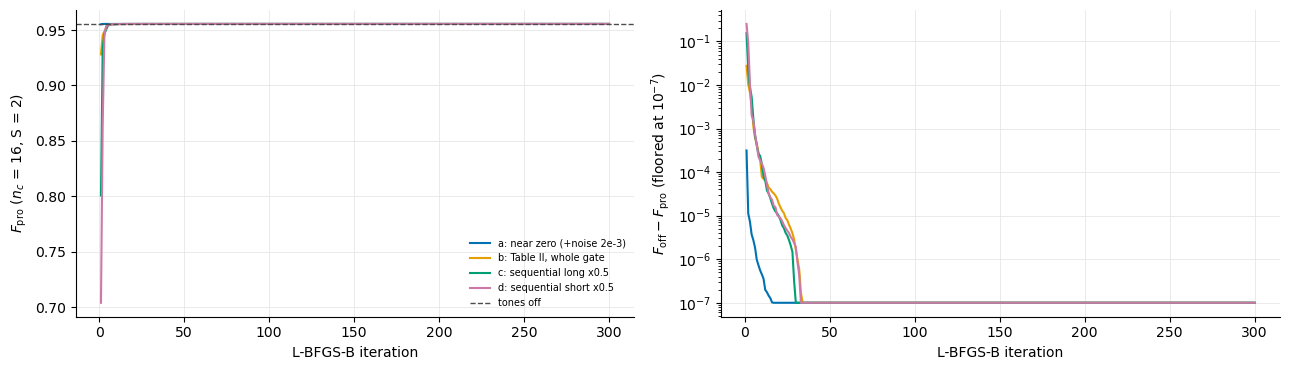

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for (tag, info), col in zip(runs.items(), OKABE):
    h = pd.DataFrame(info["history"])
    if h.empty:
        continue
    lab = f"{tag.replace('X_fwm_s2_', '')}: {START_LABEL.get(os.path.basename(info['init_x']), '')}"
    axes[0].plot(h.it, h.F_pro, color=col, lw=1.5, label=lab)
    axes[1].semilogy(h.it, np.maximum(F_OFF16 - h.F_pro, 1e-7), color=col, lw=1.5, label=lab)
axes[0].axhline(F_OFF16, color="0.3", ls="--", lw=1, label="tones off")
axes[0].set_ylabel(r"$F_{\rm pro}$ ($n_c$ = 16, S = 2)")
axes[1].set_ylabel(r"$F_{\rm off} - F_{\rm pro}$ (floored at $10^{-7}$)")
for ax in axes:
    ax.set_xlabel("L-BFGS-B iteration")
    tidy(ax)
axes[0].legend(fontsize=7, frameon=False)
fig.tight_layout()
fig.savefig("figures/fwm_grape_stage2_convergence.png", dpi=150)
plt.show()

**Figure 5. Convergence of the four Stage 2 runs.** Left: $F_{\rm pro}$ per iteration; dashed: tones off. Right: the
distance below tones off, on a log scale (a run above tones off would drop out of the plot).

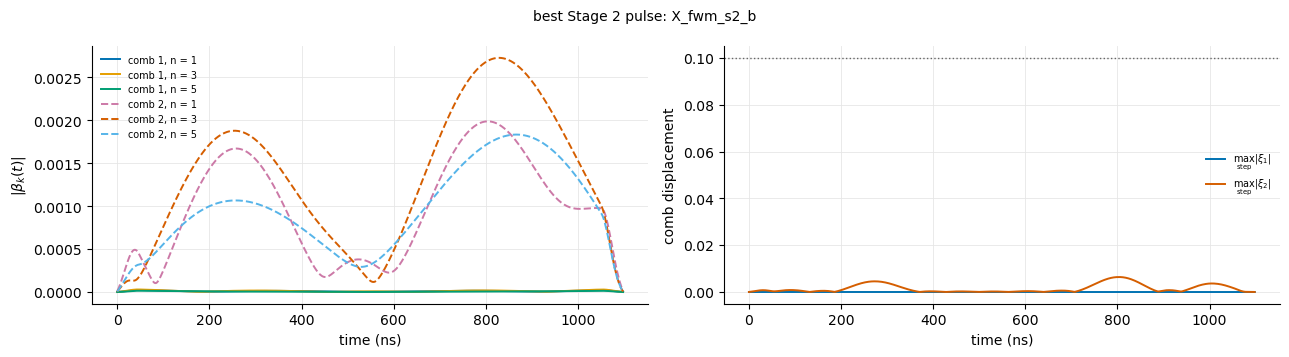

In [20]:
best_tag = max(runs, key=lambda t: runs[t]["F_pro"])
b_best = np.load(f"pulses/dgrape/b_{best_tag}.npy")
tt = fwm.node_times(N_D2, DT, 2)
ph = np.exp(1j * fw16.Delta[None, :, None] * tt[:, None, :])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for k, (c, n) in enumerate(fwm.TONES):
    axes[0].plot(np.arange(N_D2) * DT * 1e3, np.abs(b_best[:, k]), color=OKABE[k], lw=1.4,
                 ls="-" if c == 1 else "--", label=f"comb {c}, n = {n}")
for c, col in ((1, OKABE[0]), (2, OKABE[4])):
    xi_c = np.abs((b_best[:, fw16.comb == c, None] * ph[:, fw16.comb == c]).sum(1)).max(1)
    axes[1].plot(np.arange(N_D2) * DT * 1e3, xi_c, color=col, lw=1.4, label=fr"$\max_{{\rm step}}|\xi_{c}|$")
axes[1].axhline(fwm.BETA_CAP, color="0.4", ls=":", lw=1)
axes[0].set_ylabel(r"$|\beta_k(t)|$")
axes[1].set_ylabel("comb displacement")
for ax in axes:
    ax.set_xlabel("time (ns)")
    ax.legend(fontsize=7, frameon=False)
    tidy(ax)
fig.suptitle(f"best Stage 2 pulse: {best_tag}", fontsize=10)
fig.tight_layout()
fig.savefig("figures/fwm_grape_stage2_best_tones.png", dpi=150)
plt.show()

**Figure 6. The tones of the best Stage 2 run.** Left: envelope moduli $|\beta_k(t)|$ (solid comb 1, dashed comb 2).
Right: the largest comb displacement within each step, against the cap.

In [21]:
held = pd.read_csv("tables/fwm_stage2_heldout.csv")
order = ["train", "S4", "S8", "nc18", "nc20", "nr3", "all_ch", "g/sqrt2", "beta_x0.9", "beta_x1.1",
         "stark_off", "mix1", "mix2", "closed", "loss_only", "t1_only"]
pivF = held.pivot(index="condition", columns="tag", values="F_pro").reindex(order)
pivG = held.pivot(index="condition", columns="tag", values="gain_vs_off").reindex(order)
tags = [t for t in pivF.columns if t != "off"]
tab = pd.DataFrame({"tones off": pivF["off"]})
for t in tags:
    tab[f"{t.replace('X_fwm_s2_', '')}: F"] = pivF[t]
    tab[f"{t.replace('X_fwm_s2_', '')}: gain"] = pivG[t]
display(tab.style.format({c: ("{:+.5f}" if "gain" in c else "{:.5f}") for c in tab.columns})
        .set_caption("Table 12. Held-out scoring (DGRAPE/fwm_score.py). Every condition differs from training "
                     "(n_c 16, CF4 S 2, decay set, mixing off) in one setting only; gain = F - F(tones off, same condition)."))
tr = held[held.condition == "train"].set_index("tag")
display(tr[["F_pro", "n_r_end", "P_f_end", "C_forbid", "C_transmon", "mean_transmon_excitation"]]
        .style.format("{:.3e}").set_caption("Table 13. Occupations at the training condition (C sums over 550 steps "
                                            "and the two code inputs, as DGRAPE)."))
split2 = pd.DataFrame({t: {"photon-loss cost": pivF.loc["closed", t] - pivF.loc["loss_only", t],
                           "transmon T1 cost": pivF.loc["closed", t] - pivF.loc["t1_only", t],
                           "closed-system F": pivF.loc["closed", t]} for t in pivF.columns}).T
display(split2.style.format("{:.4f}").set_caption("Table 14. Table 1's channel split with the tones on (n_c = 16, n_r = 2, S = 2)."))

,tones off,a: F,a: gain,b: F,b: gain,c: F,c: gain,d: F,d: gain
condition,,,,,,,,,
train,0.95555,0.95556,+0.00001,0.95556,+0.00001,0.95556,+0.00001,0.95556,+0.00001
S4,0.95555,0.95556,+0.00001,0.95556,+0.00001,0.95556,+0.00001,0.95556,+0.00001
S8,0.95555,0.95556,+0.00001,0.95556,+0.00001,0.95556,+0.00001,0.95556,+0.00001
nc18,0.95555,0.95556,+0.00001,0.95556,+0.00001,0.95556,+0.00001,0.95556,+0.00001
nc20,0.95556,0.95556,+0.00001,0.95556,+0.00001,0.95556,+0.00001,0.95556,+0.00001
nr3,0.95555,0.95556,+0.00001,0.95556,+0.00001,0.95556,+0.00001,0.95556,+0.00001
all_ch,0.94472,0.94473,+0.00001,0.94473,+0.00001,0.94473,+0.00001,0.94473,+0.00001
g/sqrt2,0.95555,0.95556,+0.00001,0.95556,+0.00001,0.95556,+0.00001,0.95556,+0.00001
beta_x0.9,0.95555,0.95556,+0.00001,0.95556,+0.00001,0.95556,+0.00001,0.95556,+0.00001


,F_pro,n_r_end,P_f_end,C_forbid,C_transmon,mean_transmon_excitation
tag,,,,,,
off,9.556e-01,0.000e+00,1.444e-08,1.010e+01,6.361e+02,5.782e-01
X_fwm_s2_a,9.556e-01,1.085e-11,1.111e-08,1.009e+01,6.362e+02,5.783e-01
X_fwm_s2_b,9.556e-01,1.527e-11,1.028e-08,1.009e+01,6.362e+02,5.783e-01
X_fwm_s2_c,9.556e-01,1.950e-11,1.134e-08,1.009e+01,6.362e+02,5.783e-01
X_fwm_s2_d,9.556e-01,1.517e-11,1.012e-08,1.009e+01,6.362e+02,5.783e-01


,photon-loss cost,transmon T1 cost,closed-system F
X_fwm_s2_a,0.0240,0.0119,0.9911
X_fwm_s2_b,0.0240,0.0119,0.9911
X_fwm_s2_c,0.0240,0.0119,0.9911
X_fwm_s2_d,0.0240,0.0119,0.9911
off,0.0240,0.0119,0.9911



**Reading Tables 11–14 and Figures 5–6.**

- **Verdict: no-go for Stage 2.** The best run (b) reaches $F_{\rm pro} = 0.955561$ at $n_c = 16$, a gain of
  $+6.2\times10^{-6}$ over tones off ($0.955554$). The threshold was $+3\times10^{-3}$.
- **The four starts reach one pulse.** Runs a–d start at $F$ = 0.9552, 0.9280, 0.8007 and 0.7038 (Table 11) and
  all end within $10^{-7}$ of each other. Each used its full 300 iterations (about 6.5 h). The cost had stopped
  moving long before: it changed by less than $10^{-8}$ over the last iterations (Figure 5). Running longer would
  not change the answer.
- **The optimizer switches the tones off.** Comb 1, the tones that put a lost photon back, ends at
  $\max|\xi_1| = 1.4\times10^{-5}$, which is zero in practice. Comb 2 keeps a small $\max|\xi_2| = 0.0065$, 15
  times below the cap. No pre-image entry reaches the box (0 % pinned). The cap and the penalties never bind, so
  the result is not an artifact of the limits of §3.
- **The small gain is not a repair.** Two numbers show this. (i) With the Stark shift switched off (`stark_off`)
  the gain drops to $5\times10^{-9}$. All $6\times10^{-6}$ come from the tones' small frequency shift of the
  transmon, a slight retuning of the gate. (ii) Table 14's photon-loss cost is 0.02396 with and without the
  tones, and $\langle\hat n_r\rangle(T_g) = 10^{-11}$: nothing is pumped into the readout, so no lost photon was
  returned.
- **The result is solid in every held-out condition** (Table 12). The gain is $(6.1 \pm 0.1)\times10^{-6}$ at
  $S$ = 2, 4 and 8, at $n_c$ = 16, 18 and 20, with $n_r = 3$, with $g/\sqrt2$, with pump mixing $s$ = 1 or 2, and
  with $\beta \times 0.9$ or $1.1$. With all channels on it is $7.4\times10^{-6}$. The training settings are
  converged: tones-off $F$ moves by $10^{-6}$ from $n_c$ = 16 to 20 and by less than $10^{-7}$ from $S$ = 2 to 8.
- **Pump mixing does not matter here.** The $a^\dagger r^\dagger$ term of §2.6 scales as $\xi_1\xi_2$; with comb 1 at $10^{-5}$ it is far below 1 Hz.
  `mix1` and `mix2` agree with `train` to $10^{-9}$. The term still matters at the cap (§2.6), where Stage 3 may go.
- **Why, in one paragraph.** Repair needs comb 1 and then comb 2, so the gain grows as $|\beta|^4$. The harm
  grows as $|\beta|^2$: the tones Stark-shift the gate's own lines, which d2 cannot follow because it is frozen.
  The scan (Table 10) already showed that every start with real tone strength costs fidelity: 2.8 % for Table II as given, 87 % at three times Table II, 99 % at nine times. The
  landscape slopes down to zero tones from every start we tried, which is what §6.2 predicted before the run.


# 7. The full comb: 9 teeth per comb

**Question.** Stage 2 used Shirol's six tones. They repair a loss only from the odd code words: $0 \to 1$, $2 \to 3$,
$4 \to 5$. During a gate, though, the state leaves the code space and passes through many photon numbers, so a photon
lost mid-gate can come from any Fock state. Does a comb with a tooth for **every** repair $n-1 \to n$, $n = 1, \dots, 9$,
give the frozen d2 gate something the six tones could not?

**What changes against §6.**

- **18 tones:** 9 teeth per comb, paths $n = 1, \dots, 9$ (`fwm.FULL_PATHS`; `paths=` in `fwm.fwm_terms`,
  `--paths` in the three scripts). The tooth $9 \to 10$ is left out on purpose: Fock 10 is where DGRAPE's forbidden
  region starts (`forbid_fock_min`).
- **Band ±1 MHz** on each envelope (`fwm.BETA_BAND_FULL`). Neighbouring teeth are now $\chi_{gf}/2\pi$ = 2.07 MHz
  apart, and ±2 MHz would overlap them.
- Everything else is the Stage 2 recipe of §3 and §6.4: d2 frozen, cap 0.1 per tone and per comb, the same penalty
  weights (Table 8), $n_c = 16$, CF4 $S = 2$.

## 7.1 Why more teeth

The cell runs the d2 gate (tones off, $n_c = 16$) from $|0_L\rangle$ and $|1_L\rangle$ and records the storage
photon-number distribution $P_n(t)$, summed over the transmon and readout. A storage photon is lost from Fock $n$ at
the rate $\kappa_a n P_n(t)$, and the state lands in $n - 1$. The tooth that would put it back is "path $n$". So the
time integral of $\kappa_a n P_n$ is the expected number of loss jumps each tooth could act on (Table 15).

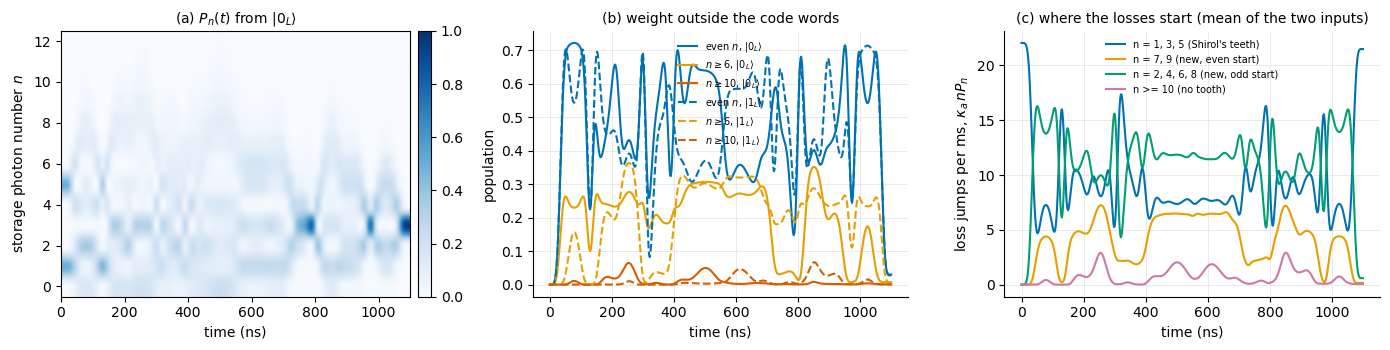

,repair (tooth),expected jumps from n,share,tooth in
n,,,,
1,0 -> 1,1.28e-03,4.6%,six and 18
2,1 -> 2,2.52e-03,9.1%,18 only
3,2 -> 3,4.63e-03,16.6%,six and 18
4,3 -> 4,3.63e-03,13.0%,18 only
5,4 -> 5,4.39e-03,15.7%,six and 18
6,5 -> 6,3.75e-03,13.5%,18 only
7,6 -> 7,3.27e-03,11.7%,18 only
8,7 -> 8,2.37e-03,8.5%,18 only
9,8 -> 9,1.26e-03,4.5%,18 only


share of jumps per group: n = 1, 3, 5 (Shirol's teeth) 36.9%; n = 7, 9 (new, even start) 16.2%; n = 2, 4, 6, 8 (new, odd start) 44.1%; n >= 10 (no tooth) 2.8%
max even-n weight during the gate 0.72, at T_g 0.024; max weight at n >= 6 0.36, at n >= 10 0.067


In [22]:
# Storage photon-number distribution during d2 (tones off, n_c = 16) and where the photon losses start
B16 = embedded_basis(16)
rho_L = np.stack([np.outer(B16[:, k], B16[:, k].conj()) for k in (0, 1)])
R_end71, hist71 = fwm.propagate(m16, fw16, U_D2, np.zeros((N_D2, 6)), DT, 1, rho_L, store=True)
diag71 = np.real(np.array([np.diagonal(R, axis1=1, axis2=2) for R in hist71 + [R_end71]]))
P_n = diag71.reshape(N_D2 + 1, 2, 16, 3, 2).sum(axis=(3, 4))       # (time, input |0_L>/|1_L>, n)
n16 = np.arange(16)
t71 = np.arange(N_D2 + 1) * DT * 1e3                                  # ns
jump_rate = dev.kappa_a * n16[None, None, :] * P_n                    # loss jumps per us, by starting Fock n
groups = {"n = 1, 3, 5 (Shirol's teeth)": [1, 3, 5], "n = 7, 9 (new, even start)": [7, 9],
          "n = 2, 4, 6, 8 (new, odd start)": [2, 4, 6, 8], "n >= 10 (no tooth)": list(range(10, 16))}

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
im = axes[0].imshow(P_n[:, 0, :13].T, aspect="auto", origin="lower", cmap="Blues",
                    extent=[0, t71[-1], -0.5, 12.5], vmin=0, vmax=1)
axes[0].set_ylabel("storage photon number $n$")
axes[0].set_title(r"(a) $P_n(t)$ from $|0_L\rangle$", fontsize=10)
fig.colorbar(im, ax=axes[0], fraction=0.05, pad=0.02)
for b, ls in ((0, "-"), (1, "--")):
    lab = r"$|0_L\rangle$" if b == 0 else r"$|1_L\rangle$"
    axes[1].plot(t71, P_n[:, b, n16 % 2 == 0].sum(1), color=OKABE[0], ls=ls, lw=1.5, label=f"even $n$, {lab}")
    axes[1].plot(t71, P_n[:, b, 6:].sum(1), color=OKABE[1], ls=ls, lw=1.5, label=f"$n \\geq 6$, {lab}")
    axes[1].plot(t71, P_n[:, b, 10:].sum(1), color=OKABE[4], ls=ls, lw=1.5, label=f"$n \\geq 10$, {lab}")
axes[1].set_ylabel("population")
axes[1].set_title("(b) weight outside the code words", fontsize=10)
for (lab, ns), col in zip(groups.items(), OKABE):
    axes[2].plot(t71, 1e3 * jump_rate[:, :, ns].sum(2).mean(1), color=col, lw=1.5, label=lab)
axes[2].set_ylabel(r"loss jumps per ms, $\kappa_a\,n P_n$")
axes[2].set_title("(c) where the losses start (mean of the two inputs)", fontsize=10)
for ax in axes:
    ax.set_xlabel("time (ns)")
for ax in axes[1:]:
    ax.legend(fontsize=7, frameon=False)
    tidy(ax)
fig.tight_layout()
fig.savefig("figures/fwm_grape_full_comb_fock.png", dpi=150)
plt.show()

J71 = np.trapz(jump_rate, dx=DT, axis=0).mean(0)                     # expected jumps over the gate, by n
loss_table = pd.DataFrame({"repair (tooth)": [f"{n - 1} -> {n}" for n in range(1, 12)],
                           "expected jumps from n": J71[1:12], "share": J71[1:12] / J71.sum(),
                           "tooth in": ["six and 18" if n in (1, 3, 5) else ("18 only" if n <= 9 else "none")
                                        for n in range(1, 12)]}, index=pd.Index(range(1, 12), name="n"))
display(loss_table.style.format({"expected jumps from n": "{:.2e}", "share": "{:.1%}"})
        .set_caption(f"Table 15. Expected photon-loss jumps during d2 by starting Fock n (n_c = 16, tones off, mean of "
                     f"|0_L> and |1_L>). Total {J71.sum():.4f} per gate."))
print("share of jumps per group: " + "; ".join(f"{k} {J71[v].sum() / J71.sum():.1%}" for k, v in groups.items()))
print(f"max even-n weight during the gate {P_n[:, :, n16 % 2 == 0].sum(2).max():.2f}, at T_g "
      f"{P_n[-1, :, n16 % 2 == 0].sum(1).max():.3f}; max weight at n >= 6 {P_n[:, :, 6:].sum(2).max():.2f}, "
      f"at n >= 10 {P_n[:, :, 10:].sum(2).max():.3f}")

**Figure 7 and Table 15.** (a) The storage photon-number distribution during d2 from $|0_L\rangle$. (b) The weight
in even photon numbers, at $n \ge 6$ and at $n \ge 10$, from both inputs. (c) The loss-jump rate $\kappa_a n P_n(t)$,
grouped by which tooth could repair it.

- **The gate spends most of its time outside the code words.** Mid-gate, even photon numbers hold up to 72 % of the
  population, and up to 36 % sits at $n \ge 6$. By $T_g$ the even weight is back down to about 3 %.
- **So most losses start from photon numbers that Shirol's teeth do not cover.** Paths 1, 3, 5 see 37 % of the
  expected jumps. The new teeth see 60 %: 16 % at $n$ = 7, 9 and 44 % at $n$ = 2, 4, 6, 8. Only 3 % start at
  $n \ge 10$, where there is no tooth. The full comb covers 97 %.
- The total, 0.028 jumps per gate, fits the 2.4 % photon-loss cost of Table 1.
- **Covering a loss is necessary, not sufficient.** A loss from a superposition multiplies each component by
  $\sqrt n$. Putting the photon back fixes the photon number but not those weights. Mid-gate, the frozen gate then
  goes on acting on a state it was not trained for.

## 7.2 The teeth

The cell lists the 18 teeth (Table 16), on the same footing as Table 3:

- the carrier, and the distance to the nearest tooth of the same comb;
- the Table II rule extended to every path (comb 1 at $0.0033/\sqrt n$, the same 57 kHz on every path; comb 2 at 0.011;
  `fwm.beta_table2`);
- the swap rate at Table II, at the cap ($|\beta| = 0.1$), and at cap/9, the share each tooth gets when nine teeth
  split the comb cap evenly;
- the **neighbour contrast**: how fully a tooth at the cap also swaps the neighbouring path $n + 1$, detuned by the
  tooth spacing $\delta$: $4\Omega'^2/(4\Omega'^2 + \delta^2)$, with $\Omega'$ the neighbour path's rate at the same
  $\beta$ (the Rabi contrast of §2.5).

In [23]:
fwF = fwm.fwm_terms(m12, paths=fwm.FULL_PATHS)
t2F = fwm.beta_table2(fwm.FULL_PATHS)
rows = []
for k, (c, n) in enumerate(fwF.tones):
    same = [j for j, (cc, _) in enumerate(fwF.tones) if cc == c and j != k]
    step = min(abs(mhz(fwF.Delta[j] - fwF.Delta[k])) for j in same)
    contrast = np.nan
    if n < 9:
        om_nb = mhz(fwm.tone_rate(fwF.tones.index((c, n + 1)), fwm.BETA_CAP, tones=fwF.tones))
        contrast = 4 * om_nb ** 2 / (4 * om_nb ** 2 + step ** 2)
    rows.append({"tooth": f"comb {c}, n = {n}", "starts from": "even n-1" if n % 2 else "odd n-1",
                 "carrier Delta/2pi (MHz)": mhz(fwF.Delta[k]), "nearest tooth (MHz)": step, "Table II beta": t2F[k],
                 "rate at Table II (kHz)": 1e3 * mhz(fwm.tone_rate(k, t2F[k], tones=fwF.tones)),
                 "rate at cap (MHz)": mhz(fwm.tone_rate(k, fwm.BETA_CAP, tones=fwF.tones)),
                 "rate at cap/9 (kHz)": 1e3 * mhz(fwm.tone_rate(k, fwm.BETA_CAP / 9, tones=fwF.tones)),
                 "neighbour contrast at cap": contrast})
display(pd.DataFrame(rows).style.hide(axis="index")
        .format({"carrier Delta/2pi (MHz)": "{:+.3f}", "nearest tooth (MHz)": "{:.3f}", "Table II beta": "{:.4f}",
                 "rate at Table II (kHz)": "{:.0f}", "rate at cap (MHz)": "{:.2f}", "rate at cap/9 (kHz)": "{:.0f}",
                 "neighbour contrast at cap": "{:.2f}"}, na_rep="-")
        .set_caption("Table 16. The 18 teeth of the full comb (n_c = 12 carriers). Rates on the tooth's own path."))
for band in (fwm.BETA_BAND_FULL, fwm.BETA_BAND):
    print(f"band {band} MHz keeps {make_band_mask(N_D2, DT, *band).sum()} frequency bins per tooth")
print(f"comb-1 swap at n = 1 with cap/9: {np.pi / 2 / fwm.tone_rate(0, fwm.BETA_CAP / 9, tones=fwF.tones):.2f} us; "
      f"own-line Stark detuning (538 MHz |xi|^2) reaches 1 MHz at |xi| = {np.sqrt(1 / 538):.3f}")

tooth,starts from,carrier Delta/2pi (MHz),nearest tooth (MHz),Table II beta,rate at Table II (kHz),rate at cap (MHz),rate at cap/9 (kHz),neighbour contrast at cap
"comb 1, n = 1",even n-1,+136.350,2.069,0.0033,57,1.73,193,0.85
"comb 1, n = 2",odd n-1,+138.419,2.066,0.0023,57,2.45,273,0.89
"comb 1, n = 3",even n-1,+140.485,2.062,0.0019,57,3.00,334,0.92
"comb 1, n = 4",odd n-1,+142.547,2.058,0.0016,57,3.47,385,0.93
"comb 1, n = 5",even n-1,+144.605,2.054,0.0015,57,3.88,431,0.94
"comb 1, n = 6",odd n-1,+146.660,2.051,0.0013,57,4.25,472,0.95
"comb 1, n = 7",even n-1,+148.710,2.047,0.0012,57,4.59,510,0.96
"comb 1, n = 8",odd n-1,+150.757,2.043,0.0012,57,4.91,545,0.96
"comb 1, n = 9",even n-1,+152.800,2.043,0.0011,57,5.20,578,-
"comb 2, n = 1",even n-1,-136.350,2.066,0.0110,192,1.74,194,0.74


band (-1.0, 1.0) MHz keeps 3 frequency bins per tooth
band (-2.0, 2.0) MHz keeps 5 frequency bins per tooth
comb-1 swap at n = 1 with cap/9: 1.30 us; own-line Stark detuning (538 MHz |xi|^2) reaches 1 MHz at |xi| = 0.043


**Reading Table 16.**

- **The teeth are 2.04–2.07 MHz apart.** Both combs step by about $\chi_{gf}$ per photon: comb 1 upward from
  +136.35 MHz, comb 2 downward from −136.35 MHz. Kerr and $\chi'$ shrink the step by about 4 kHz per photon.
- **At the cap a tooth cannot tell its path from the neighbouring one.** The neighbour contrast at $|\beta| = 0.1$ is
  0.74–0.96, so a tooth at the cap swaps the next path almost as fully as its own. To pick out one path the rate has to
  stay well below half the spacing (about 1 MHz). For comb 1 at low $n$ that means $|\beta| \lesssim 0.03$, and less at
  high $n$, where the matrix element grows as $\sqrt{2n}$. With six tones 4.14 MHz apart this problem was milder.
- **The cap is shared.** All nine teeth of a comb add into one $\xi_c$, and $|\xi_c| \le 0.1$. If they split it
  evenly, each tooth gets 0.011, and a comb-1 swap at $n = 1$ takes 1.3 μs, longer than the whole gate. Strong teeth
  have to take turns.
- **Band ±1 MHz keeps 3 frequency bins per tooth** (printed): 18 × 3 × 2 = **108 real degrees of freedom**, against
  60 for six tones. It is half the tooth spacing, the same rule that set ±2 MHz in §3. It also halves the room for
  retuning a tooth by a phase ramp: a tooth's own Stark detuning reaches 1 MHz at $|\xi| \approx 0.043$ (§2.5).
- **The Table II rule extended to nine teeth is not small.** Comb 2 at 0.011 on nine teeth adds up to
  $|\xi_2| \approx 0.099$ when the phases align, right at the cap. There, the gate's own $g \to e$ line moves by
  about 2.7 MHz (§2.5).
- **Cost.** One evaluation (F and the exact gradient, $n_c = 16$, $S = 2$, 3 jobs, alone on the i7-13700KF) takes
  48 s with the tones off for both tone sets. With every tooth at 0.1 it takes 62 s with six tones and 138 s with 18.
  The norm bound sums $|\beta|$ per comb, so at the cap it is three times the six-tone bound, and the Taylor order
  goes from 21 to 46. The bound is kept: it is a true bound, and real pulses sit far below it.

## 7.3 Prediction, recorded before training

Written on 2026-10-12, before the scan and the runs of §7.4.

1. **Everything behind §6.2 still holds.** d2 is frozen. Any comb displacement moves the gate's $g \to e$ line by
   $2\alpha|\xi|^2$, and d2 cannot follow. $\beta = 0$ is a local maximum: a repair needs comb 1 and comb 2, so its
   gain is fourth order in $\beta$, while crosstalk costs at second order.
2. **Half the new teeth pump the code words out of the code.** Teeth that start from an odd $n - 1$ ($1 \to 2$,
   $3 \to 4$, $5 \to 6$, $7 \to 8$) act on $|1\rangle, |3\rangle, |5\rangle$ themselves. They must be off at
   $T_g$, and any time they are on mid-gate they act on the gate's non-error states too. GRAPE's envelopes have to
   learn this. Nothing pushes them to.
3. **Unresolved teeth.** A tooth strong enough to swap within the gate also drives its neighbour paths (Table 16).
4. **A shared cap.** Nine teeth share $|\xi_c| \le 0.1$, so each one is slower than in §6.
5. **A higher ceiling, but not a usable one.** The new teeth cover 60 % of the expected loss jumps (Table 15).
   A repair mid-gate helps only if the frozen gate then finishes correctly from the repaired state, and it was never
   trained to.

**Expected: a null or very small result.** The runs should end with the tones near zero and $F$ within about
$10^{-5}$ of tones off (0.955554), as in §6, far below the 0.3 % go threshold. A gain above $10^{-4}$ that survives
held-out $S$, $n_c$, $g/\sqrt2$ and Stark-off would be a surprise worth following up.

## 7.4 Landscape scan and protocol

As in §6.3, $\beta = 0$ is a local maximum, so the runs have to start where a repair could work.
`DGRAPE/fwm_stage2_scan.py --paths 1 2 3 4 5 6 7 8 9` scored 16 starts, each passed through the 18-tone training
chain (band ±1 MHz), at the training settings ($n_c = 16$, CF4 $S = 2$). The starts are those of §6.3 rebuilt for
18 teeth (`fwm.beta_table2`, and per-tooth swap amplitudes). The scan adds **"even start"** variants of the sequential
repairs: the same windows and amplitudes, but only the teeth that start from an even $n - 1$ ($n$ = 1, 3, 5, 7, 9).
These are the teeth that cannot pump the code words out.

In [24]:
scanF = pd.read_csv("tables/fwm_stage2_full_scan.csv")
display(scanF[cols].sort_values("F_pro", ascending=False).style.hide(axis="index")
        .format({"F_pro": "{:.4f}", "change_vs_off": "{:+.4f}", "F_pro_mix1": "{:.4f}", "max_beta": "{:.3f}",
                 "max_xi_1": "{:.3f}", "max_xi_2": "{:.3f}", "P_f_end": "{:.1e}", "n_r_end": "{:.1e}"})
        .set_caption("Table 17. Landscape scan with 18 teeth (band ±1 MHz), training settings (n_c = 16, CF4 S = 2). "
                     "'evenstart': only the teeth n = 1, 3, 5, 7, 9."))
print(f"tones off: {float(scanF.loc[scanF.start == 'off', 'F_pro'].iloc[0]):.6f} (d2: {F_OFF16:.6f}); "
      f"largest change from the pump-mixing term: {np.abs(scanF.F_pro_mix1 - scanF.F_pro).max():.1e}")

start,F_pro,change_vs_off,F_pro_mix1,max_beta,max_xi_1,max_xi_2,P_f_end,n_r_end
off,0.9556,+0.0000,0.9556,0.000,0.000,0.000,1.4e-08,0.0e+00
tableII_x3_last0.5,0.8228,-0.1328,0.8231,0.036,0.044,0.278,8.3e-03,1.9e-03
seq_long_f0.5_evenstart,0.7661,-0.1894,0.7662,0.018,0.044,0.085,6.3e-02,7.0e-03
seq_short_f0.5_evenstart,0.7416,-0.2140,0.7416,0.019,0.051,0.092,5.2e-02,6.9e-03
tableII_x1_full,0.6986,-0.2570,0.6986,0.011,0.016,0.099,9.0e-03,1.4e-03
seq_long_comb2_only,0.5642,-0.3914,0.5642,0.035,0.000,0.307,3.5e-08,7.8e-10
seq_long_f0.5,0.3479,-0.6077,0.3479,0.018,0.076,0.153,1.0e-01,2.5e-02
tableII_x3_full,0.3298,-0.6258,0.3301,0.033,0.047,0.297,1.3e-02,3.8e-03
seq_short_f0.5,0.2496,-0.7059,0.2496,0.019,0.044,0.166,6.0e-02,1.3e-02
tableII_x9_last0.5,0.1159,-0.8397,0.1160,0.107,0.131,0.833,2.0e-02,1.4e-02


tones off: 0.955554 (d2: 0.955554); largest change from the pump-mixing term: 8.0e-04


**Reading Table 17.**

- **With the tones off, the 18-tone model is the d2 gate**: 0.955554, the same as Table 10.
- **Every start scores below tones off, by more than with six tones.** The Table II rule on all 18 teeth, over the whole
  gate, costs 26 % (2.8 % with six). Comb 2's nine teeth at 0.011 add up to $|\xi_2| = 0.099$, and the gate's
  $g \to e$ line moves with it.
- **The teeth that start from an odd $n-1$ do the most damage**, as point 2 of §7.3 expected. The "long" sequential
  repair at half the swap amplitude costs 61 % with all teeth and 19 % with only the even-start teeth. The "short"
  one costs 71 % and 21 %.
- **Comb 2 alone in the last 0.35 μs costs 39 %**, while leaving $P_f(T_g) = 4\times10^{-8}$: once more the Stark shift
  of the gate's transmon line, not crosstalk.
- The pump-mixing term changes $F$ by at most $8\times10^{-4}$, at starts that are already far below tones off.
- **Starts chosen for the runs:** the three best, Table II ×3 in the last 0.5 μs (0.823), "long" ×0.5 even start
  (0.766) and "short" ×0.5 even start (0.742), plus near-zero tones as the control, as in §6.

**Protocol (as run).**

1. **Variables:** $x_\beta$, $(550, 36)$; $u = u_{d2}$ fixed.
2. **Starts:** a = near zero (noise $2\times10^{-3}$, seed 1: the §6 control), b = Table II ×3 in the last 0.5 μs,
   c = "long" ×0.5 even start, d = "short" ×0.5 even start. They ran as four
   `DGRAPE/train_fwm.py --paths 1 2 3 4 5 6 7 8 9 --band -1 1` jobs side by side on one machine (i7-13700KF, 4 runs ×
   3 parallel jobs), tags `X_fwm_s2full_{a,b,c,d}`.
3. **Settings:** as §6.4 except the 18 teeth and the ±1 MHz band: CF4 $S = 2$, $n_c = 16$, decay set, higher-order
   terms on, cap 0.1 per tone and per comb, weights of Table 8, L-BFGS-B with `gtol` $10^{-12}$, at most 300
   iterations or 14 h, best-vs-final kept.
4. **Diagnostics:** `DGRAPE/fwm_score.py` under the 16 conditions of Table 12, including $n_c$ = 18, 20,
   $S$ = 4, 8 and the occupations $C_{\rm forbid}$, $C_T$. The results go to `tables/fwm_stage2_full_heldout.csv`
   (the six-tone table stays as it is).
5. **Go / no-go:** as §6.4, a gain of at least 0.3 % over tones off at converged $n_c$, held-out $S$ agreeing to
   $10^{-4}$, and $\max_t|\xi_c| \le 0.1$.

## 7.5 Results

The four runs (Table 18) used their full 300 iterations, about 7.3 h each with four runs sharing the machine.
Figure 8 shows how they converged, Figure 9 the tones of the best run, and Tables 19–21 the held-out scoring
(`tables/fwm_stage2_full_heldout.csv`).

In [25]:
runsF = {}
for p in sorted(glob.glob("pulses/dgrape/X_fwm_s2full_*.json")):
    info = json.load(open(p))
    runsF[info["tag"]] = info
START_LABEL_F = {"start_off.npy": "near zero (+noise 2e-3)", "start_tableII_x3_last0.5.npy": "Table II x3, last 0.5 us",
                 "start_seq_long_f0.5_evenstart.npy": "sequential long x0.5, even start",
                 "start_seq_short_f0.5_evenstart.npy": "sequential short x0.5, even start"}
F_SIX = max(info["F_pro"] for info in runs.values())                 # best six-tone Stage 2 run (§6.5)
rows = []
for tag, info in runsF.items():
    rows.append({"run": tag.replace("X_fwm_s2full_", ""),
                 "start": START_LABEL_F.get(os.path.basename(info["init_x"]), info["init_x"]),
                 "F start": info["F_pro_start"], "F end": info["F_pro"], "gain vs off": info["F_pro"] - F_OFF16,
                 "vs six tones": info["F_pro"] - F_SIX, "iterations": info["nit"], "evaluations": info["n_evals"],
                 "hours": info["wall_s"] / 3600, "max |beta|": info["max_beta"], "max |xi_1|": info["max_xi_1"],
                 "max |xi_2|": info["max_xi_2"], "x pinned": info["frac_preimage_pinned"],
                 "returned": info["returned"], "stop": info["message"][:40]})
display(pd.DataFrame(rows).style.hide(axis="index")
        .format({"F start": "{:.4f}", "F end": "{:.6f}", "gain vs off": "{:+.2e}", "vs six tones": "{:+.2e}",
                 "hours": "{:.1f}", "max |beta|": "{:.4f}", "max |xi_1|": "{:.4f}", "max |xi_2|": "{:.4f}",
                 "x pinned": "{:.2%}"})
        .set_caption(f"Table 18. Stage 2 with 18 teeth (n_c = 16, CF4 S = 2, band ±1 MHz). Tones off: {F_OFF16:.6f}; "
                     f"best six-tone run (§6.5): {F_SIX:.6f}."))

run,start,F start,F end,gain vs off,vs six tones,iterations,evaluations,hours,max |beta|,max |xi_1|,max |xi_2|,x pinned,returned,stop
a,near zero (+noise 2e-3),0.9552,0.955563,+8.96e-06,+2.80e-06,300,316,7.3,0.0019,0.0014,0.0077,0.00%,final,STOP: TOTAL NO. of ITERATIONS REACHED LI
b,"Table II x3, last 0.5 us",0.8228,0.955576,+2.15e-05,+1.54e-05,300,311,7.3,0.0059,0.0043,0.0062,0.00%,final,STOP: TOTAL NO. of ITERATIONS REACHED LI
c,"sequential long x0.5, even start",0.7661,0.955574,+1.96e-05,+1.35e-05,300,311,7.3,0.0053,0.0040,0.0066,0.00%,final,STOP: TOTAL NO. of ITERATIONS REACHED LI
d,"sequential short x0.5, even start",0.7416,0.955576,+2.19e-05,+1.58e-05,300,309,7.2,0.0058,0.0044,0.0060,0.00%,final,STOP: TOTAL NO. of ITERATIONS REACHED LI


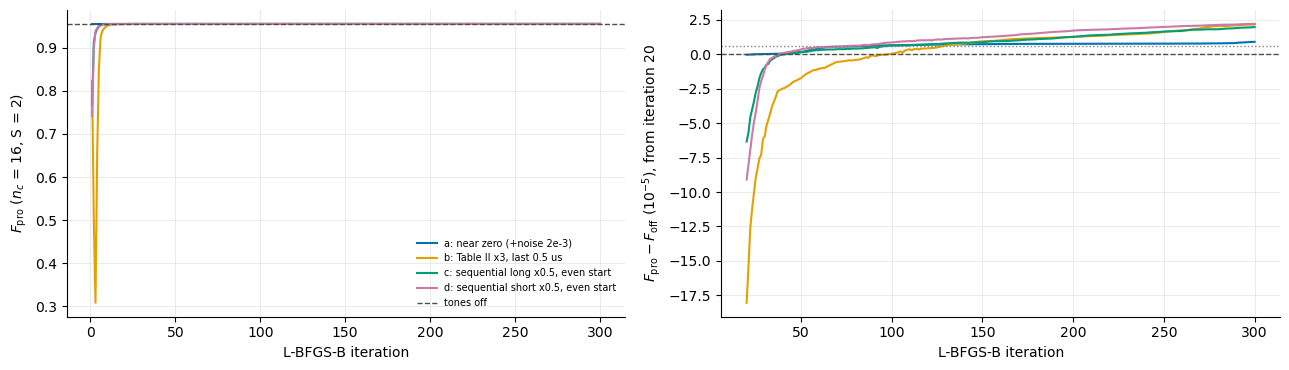

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for (tag, info), col in zip(runsF.items(), OKABE):
    h = pd.DataFrame(info["history"])
    if h.empty:
        continue
    lab = f"{tag.replace('X_fwm_s2full_', '')}: {START_LABEL_F.get(os.path.basename(info['init_x']), '')}"
    axes[0].plot(h.it, h.F_pro, color=col, lw=1.5, label=lab)
    late = h.it >= 20
    axes[1].plot(h.it[late], 1e5 * (h.F_pro[late] - F_OFF16), color=col, lw=1.5, label=lab)
axes[0].axhline(F_OFF16, color="0.3", ls="--", lw=1, label="tones off")
axes[0].set_ylabel(r"$F_{\rm pro}$ ($n_c$ = 16, S = 2)")
axes[1].axhline(0, color="0.3", ls="--", lw=1)
axes[1].axhline(1e5 * (F_SIX - F_OFF16), color="0.5", ls=":", lw=1)
axes[1].set_ylabel(r"$F_{\rm pro} - F_{\rm off}$ ($10^{-5}$), from iteration 20")
for ax in axes:
    ax.set_xlabel("L-BFGS-B iteration")
    tidy(ax)
axes[0].legend(fontsize=7, frameon=False)
fig.tight_layout()
fig.savefig("figures/fwm_grape_full_comb_convergence.png", dpi=150)
plt.show()

**Figure 8. Convergence of the four 18-tone runs.** Left: $F_{\rm pro}$ per iteration; dashed: tones off. Right: the
gain above tones off from iteration 20, in units of $10^{-5}$; dotted: the best six-tone run. The runs rise
above tones off after 26 (a), 99 (b), 42 (c) and 38 (d) iterations and are still creeping up at 300.

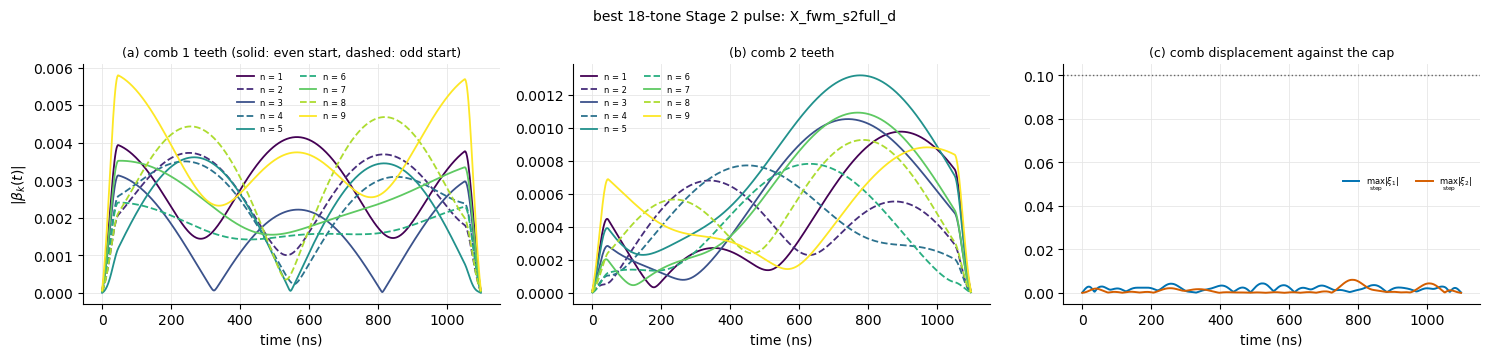

In [27]:
best_full = max(runsF, key=lambda t: runsF[t]["F_pro"])
b_full = np.load(f"pulses/dgrape/b_{best_full}.npy")
fw16F = fwm.fwm_terms(m16, paths=fwm.FULL_PATHS)
phF = np.exp(1j * fw16F.Delta[None, :, None] * tt[:, None, :])
t_ns_F = np.arange(N_D2) * DT * 1e3
cmap = plt.get_cmap("viridis")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for k, (c, n) in enumerate(fw16F.tones):
    axes[c - 1].plot(t_ns_F, np.abs(b_full[:, k]), color=cmap((n - 1) / 8), lw=1.3,
                     ls="-" if n % 2 else "--", label=f"n = {n}")
for c, col in ((1, OKABE[0]), (2, OKABE[4])):
    xi_c = np.abs((b_full[:, fw16F.comb == c, None] * phF[:, fw16F.comb == c]).sum(1)).max(1)
    axes[2].plot(t_ns_F, xi_c, color=col, lw=1.4, label=fr"$\max_{{\rm step}}|\xi_{c}|$")
axes[2].axhline(fwm.BETA_CAP, color="0.4", ls=":", lw=1)
axes[0].set_title("(a) comb 1 teeth (solid: even start, dashed: odd start)", fontsize=9)
axes[1].set_title("(b) comb 2 teeth", fontsize=9)
axes[2].set_title("(c) comb displacement against the cap", fontsize=9)
axes[0].set_ylabel(r"$|\beta_k(t)|$")
for ax in axes:
    ax.set_xlabel("time (ns)")
    ax.legend(fontsize=6, frameon=False, ncol=2)
    tidy(ax)
fig.suptitle(f"best 18-tone Stage 2 pulse: {best_full}", fontsize=10)
fig.tight_layout()
fig.savefig("figures/fwm_grape_full_comb_best_tones.png", dpi=150)
plt.show()

**Figure 9. The tones of the best 18-tone run.** (a) Comb 1 envelope moduli $|\beta_k(t)|$, one line per tooth
(solid: teeth that start from an even $n-1$, i.e. odd $n$; dashed: the others). (b) The same for comb 2. (c) The
largest comb displacement within each step, against the cap.

In [28]:
heldF = pd.read_csv("tables/fwm_stage2_full_heldout.csv")
pivFF = heldF.pivot(index="condition", columns="tag", values="F_pro").reindex(order)
pivGF = heldF.pivot(index="condition", columns="tag", values="gain_vs_off").reindex(order)
tabF = pd.DataFrame({"tones off": pivFF["off"]})
for t in [t for t in pivFF.columns if t != "off"]:
    tabF[f"{t.replace('X_fwm_s2full_', '')}: F"] = pivFF[t]
    tabF[f"{t.replace('X_fwm_s2full_', '')}: gain"] = pivGF[t]
tabF["six tones, best: gain"] = pivG[best_tag]
display(tabF.style.format({c: ("{:+.2e}" if "gain" in c else "{:.6f}") for c in tabF.columns})
        .set_caption("Table 19. Held-out scoring of the 18-tone runs (DGRAPE/fwm_score.py), the same 16 conditions as "
                     "Table 12; gain = F - F(tones off, same condition). Last column: the best six-tone run (Table 12)."))
trF = heldF[heldF.condition == "train"].set_index("tag")
display(trF[["F_pro", "n_r_end", "P_f_end", "C_forbid", "C_transmon", "mean_transmon_excitation"]]
        .style.format("{:.3e}").set_caption("Table 20. Occupations of the 18-tone runs at the training condition "
                                            "(as Table 13)."))
split3 = pd.DataFrame({t: {"photon-loss cost": pivFF.loc["closed", t] - pivFF.loc["loss_only", t],
                           "transmon T1 cost": pivFF.loc["closed", t] - pivFF.loc["t1_only", t],
                           "closed-system F": pivFF.loc["closed", t]} for t in pivFF.columns}).T
display(split3.style.format("{:.6f}").set_caption("Table 21. Table 1's channel split with the 18 tones on "
                                                  "(n_c = 16, n_r = 2, S = 2)."))

,tones off,a: F,a: gain,b: F,b: gain,c: F,c: gain,d: F,d: gain,"six tones, best: gain"
condition,,,,,,,,,,
train,0.955554,0.955563,+8.96e-06,0.955576,+2.15e-05,0.955574,+1.96e-05,0.955576,+2.19e-05,+6.16e-06
S4,0.955554,0.955563,+8.96e-06,0.955576,+2.15e-05,0.955574,+1.96e-05,0.955576,+2.20e-05,+6.16e-06
S8,0.955554,0.955563,+8.96e-06,0.955576,+2.15e-05,0.955574,+1.96e-05,0.955576,+2.20e-05,+6.16e-06
nc18,0.955555,0.955564,+9.05e-06,0.955576,+2.14e-05,0.955574,+1.95e-05,0.955577,+2.18e-05,+6.22e-06
nc20,0.955555,0.955564,+8.95e-06,0.955576,+2.04e-05,0.955574,+1.86e-05,0.955576,+2.07e-05,+6.22e-06
nr3,0.955554,0.955563,+8.96e-06,0.955576,+2.15e-05,0.955574,+1.96e-05,0.955576,+2.19e-05,+6.16e-06
all_ch,0.944722,0.944731,+8.98e-06,0.944728,+6.19e-06,0.944729,+7.01e-06,0.944728,+6.26e-06,+7.48e-06
g/sqrt2,0.955554,0.955562,+7.73e-06,0.955564,+9.89e-06,0.955564,+9.64e-06,0.955564,+1.00e-05,+6.16e-06
beta_x0.9,0.955554,0.955563,+8.71e-06,0.955574,+1.93e-05,0.955572,+1.76e-05,0.955574,+1.96e-05,+5.89e-06


,F_pro,n_r_end,P_f_end,C_forbid,C_transmon,mean_transmon_excitation
tag,,,,,,
off,9.556e-01,0.000e+00,1.444e-08,1.010e+01,6.361e+02,5.782e-01
X_fwm_s2full_a,9.556e-01,7.634e-08,1.444e-05,1.009e+01,6.362e+02,5.784e-01
X_fwm_s2full_b,9.556e-01,3.319e-07,1.412e-04,1.011e+01,6.363e+02,5.785e-01
X_fwm_s2full_c,9.556e-01,3.001e-07,1.190e-04,1.011e+01,6.363e+02,5.785e-01
X_fwm_s2full_d,9.556e-01,3.160e-07,1.451e-04,1.011e+01,6.363e+02,5.785e-01


,photon-loss cost,transmon T1 cost,closed-system F
X_fwm_s2full_a,0.023957,0.011855,0.991080
X_fwm_s2full_b,0.023961,0.011862,0.991104
X_fwm_s2full_c,0.023961,0.011861,0.991100
X_fwm_s2full_d,0.023961,0.011862,0.991104
off,0.023956,0.011851,0.991067


**Reading Tables 18–21 and Figures 8–9.**

- **Verdict: no-go, as for six tones.** The best run (d) reaches $F_{\rm pro} = 0.955576$ at $n_c = 16$, a gain of
  $+2.2\times10^{-5}$ over tones off (0.955554) and $+1.5\times10^{-5}$ over the best six-tone run (0.955561). The
  go threshold was $+3\times10^{-3}$, 140 times larger.
- **Three starts end together, the near-zero start lower.** Runs b, c and d start at $F$ = 0.823, 0.766 and 0.742
  and end within $2.4\times10^{-6}$ of each other (0.955574–0.955576). Run a, started at near-zero tones, ends at
  0.955563.
- **The runs had not quite stopped.** Unlike §6, $F$ was still rising at iteration 300: by 5–9 $\times10^{-6}$ over
  the last 100 iterations for b–d, and more slowly each time (Figure 8). Even at the run b pace for 3000 more
  iterations, the gain would stay below $3\times10^{-4}$, a tenth of the threshold. Running longer would not change
  the verdict.
- **The tones stay small, but comb 1 no longer switches off.** In b–d each comb-1 tooth ends at 0.002–0.006, largest
  at $n = 8$ and 9, and $\max|\xi_1| \approx 0.004$. Comb 2 sits at about 0.001 per tooth, $\max|\xi_2| \approx
  0.006$. Everything is 17 times or more below the cap. No pre-image entry is pinned and the amplitude and comb
  penalties are zero, so the limits of §3 and §7 never bind. The teeth that start from an odd $n-1$ (dashed in
  Figure 9) are not switched off either; at these amplitudes they barely move population.
- **The gain is not a repair.** (i) Table 21's photon-loss cost is 0.02396 with and without the tones (with them it
  is $5\times10^{-6}$ *larger*), and $\langle\hat n_r\rangle(T_g) = 3\times10^{-7}$: almost nothing reaches the
  readout, so no lost photon was returned. (ii) The gain is largest with **no** dissipation at all: $+3.7\times10^{-5}$
  in the closed system (Table 19, `closed`). The tones improve the coherent part of the gate.
- **And, unlike §6, it is not a Stark retuning.** With the Stark shift switched off the gain grows, up to
  $+2.7\times10^{-5}$ (six tones: it fell to $6\times10^{-9}$). With $g/\sqrt2$ it halves to $1.0\times10^{-5}$. So the
  gain rides on the swap coupling itself. The most likely reading: the weak comb-1 teeth act as small extra
  coherent controls between $|n{-}1,g\rangle$ and $|n,f\rangle$, which trim a little of d2's 0.9 % coherent error.
  The price is visible in Table 20: $P_f(T_g)$ goes from $1.4\times10^{-8}$ to $1.4\times10^{-4}$.
- **Held-out.** $S$ = 2, 4, 8 agree to $10^{-7}$. From $n_c$ = 16 to 18 and 20 the gain moves by at most $1.2\times10^{-6}$;
  $n_r = 3$ and pump mixing ($s$ = 1, 2) change nothing. Scaling every tone by 0.9 or 1.1 gives $1.96$ and
  $2.34\times10^{-5}$: the larger tones score *better*, another sign that the runs were still growing them. With
  all channels on (dephasing and heating) the gain drops to $6\times10^{-6}$ for b–d.
- **Against the prediction of §7.3.** The verdict, the tones ending near zero and the Stark argument for $\beta = 0$
  being hard to leave all held. The size did not, quite: $2.2\times10^{-5}$ is twice the "about $10^{-5}$" written
  down, though 5 times below the $10^{-4}$ that would have counted as a surprise. The mechanism was not predicted:
  the extra gain is coherent, not a repair. Point 2 (odd-start teeth must learn to switch off) did not come up,
  because no tooth grew strong enough to matter.
- **What this means for Stage 3.** More teeth give a frozen gate more coherent knobs, worth about $2\times10^{-5}$.
  They do not make a repair possible within a frozen gate. In Stage 3 the linear drives can make such coherent
  corrections themselves, so §8 still starts with the six tones and the idle-memory positive control.

# 8. Stage 3: joint optimization of linear drives and tones

**Question.** If the gate is allowed to change too, can the gate and the tones work together, so that a photon lost
during the gate is repaired before $T_g$ while the gate stays coherent?


**What Stage 2 implies for Stage 3.** Stage 2 asked whether tones can be *added* to a finished gate. The answer is
no. Even a modest tone moves the transmon lines by a large fraction of $\chi_{ge}$, and a frozen gate cannot follow.
Stage 3 lets $u$ change too, so the gate can absorb that shift. Stage 2 neither supports nor rules this out. Three
consequences:

1. **Do not warm-start $\beta$ from Stage 2.** It has collapsed to zero tones, and at $\beta = 0$ the repair
   gradient vanishes (gain $\propto|\beta|^4$). Start from a sequential-repair start of §6.3 with $u$ from d2.
2. **Run a positive control first.** Before spending ~10 h on a joint run, check that the model shows a repair gain
   at all where it should: an idle code-memory window ($u = 0$, 1.1 μs) with Shirol's tones, scored at the end.
   If PReSPA cannot beat idling there, a joint gate run cannot be expected to beat d2.
3. **Raise the ceiling.** About half of the 2.4 % loss cost falls in the last 0.5 μs, where no repair can finish
   by $T_g$. A longer gate, or a PReSPA tail scored after the gate, gives the tones time to work. Either is a cleaner
   test than squeezing a repair into 1.1 μs.

**What §7 adds.** The full 18-tooth comb gives the same answer. Its small extra gain is coherent, the kind of
correction the linear drives can make themselves once they are free. So Stage 3 starts with the six tones;
the full comb is worth trying only if the positive control shows a repair that needs the extra paths.


## 8.1 Protocol

1. **Variables:** $x_u$, $(550, 4)$, and $x_\beta$, $(550, 12)$: 8800 entries in total (about 60 effective for the
   tones), both boxed at 25 after scaling.
2. **Warm start:** $u$ from `pulses/dgrape/x_X_open_d2.npy` through `init_x` (exact resume, no `deramp`). $\beta$ from a
   sequential-repair start of §6.3, *not* from Stage 2's result if that has collapsed to zero tones.
3. **Cost:** $C_3$ of §5.3, weights of Table 8, CF4 $S = 2$, $n_c = 16$, forbidden-state term on.
4. **Comparisons:** d2 (0.9556, the same recipe without tones) and d3b (0.9589, the best X gate so far, trained with
   the transmon penalty). A joint run with $\lambda_{\rm transmon} = 10^{-4}$ is the like-for-like comparison with
   d3b.
5. **Expected size of the effect (honest).** The photon-loss cost of d2 is 2.4 % (Table 1). Losses in the last
   ~0.5 μs cannot be repaired by $T_g$ (about 1.1 %). The Stark limit makes a repair take about 0.5 μs. The
   transmon is busy with the gate for most of the 1.1 μs (mean $P_e + P_f$ = 0.58 for d2). Gains of a few tenths of a
   percent are a realistic target, not the full 2.4 %. A longer gate, or a PReSPA tail scored after the gate, would
   raise the ceiling.
6. **Cost per evaluation:** about 1.3× Stage 2 (the $u$ gradient comes from the same W matrices; the forbidden costate
   adds ~40 %).

## 8.2 Scoring beyond the training conditions

As in `dissipation_grape.ipynb` §11.1 and §12.1, every trained pulse is rescored under conditions it was not trained
on: the 16 conditions of Table 12 (`DGRAPE/fwm_score.py`), plus "tones off, same $u$", which shows how much of the
gain the tones carry.

## 8.3 Results (placeholder: not run)

| run | $F_{\rm pro}$ ($n_c$ = 16) | held-out $n_c$ | $S$ = 4/8 | all channels | $\pm10\%\ \beta$ | $g/\sqrt2$ | tones off | coherent / loss / T1 split |
|---|---|---|---|---|---|---|---|---|
| X, joint | — | — | — | — | — | — | — | — |
| X, joint + transmon penalty | — | — | — | — | — | — | — | — |

Saved pulses go to `pulses/dgrape/` (never `pulses/`), with tags like `X_fwm_s3`, and with $\beta$ saved next to $u$
(`b_X_fwm_s3.npy`, $(N, 6)$ complex) plus both pre-images for exact resumes.

# 9. Checklist

| # | check | status |
|---|---|---|
| 1 | Sub-stepped propagator with tones off reproduces DGRAPE | done (§4.4 check 1; test `TonesOff`) |
| 2 | Sub-step convergence against an independent solver; scheme and $S$ chosen | done (§4.4 checks 2 and 4; CF4, $S$ = 2 train, 4/8 held out) |
| 3 | One tone reproduces `fwm_tuning`'s closed form | done (§4.4 check 3) |
| 4 | Readout-traced target equals DGRAPE's when the readout is empty | done (§4.4 check 1) |
| 5 | Exact gradient: W form = augmented generator (~1e-15) = central differences (~1e-7), incl. mixing and occupation costate | done (§4.6; tests `Gradient`, `Occupation`) |
| 6 | Constraint chain for $\beta$: adjoint identity; whole objective against central differences; $n_{\rm jobs}$ = 3 equals 1 | done (test `Chain`) |
| 7 | $n_r = 2$ vs 3 | done: $<10^{-6}$ with Table II tones (test `Readout`); $2\times10^{-5}$ with strong constant tones; trained pulses in Table 12 |
| 8 | Estimate of the $\hat a^\dagger\hat r^\dagger$ pump-mixing term | done (§2.8; implemented, held-out $s$ = 1, 2) |
| 9 | Physicality of $\hat\rho$ after a long run with strong tones | done (test `Physicality`) |
| 10 | Timing of one evaluation at $n_c$ = 16 | done (§4.5) |
| 11 | Stark-compensated carriers, for tones above $\lvert\xi\rvert \approx 0.06$ | to do (Stage 3 option, §10) |
| 12 | Linear-drive × pump mixing terms | to do (estimate before Stage 3) |
| 13 | Tone set as a parameter; 18-tone comb: default unchanged, carriers $\chi_{gf}$ apart, exact gradient, chain adjoint (odd count padded) | done (§7; tests `ToneSets`) |

# 10. Open decisions

| decision | options | current choice |
|---|---|---|
| sub-step scheme and $S$ | midpoint / CF4; $S$ | CF4, $S$ = 2 for training, 4 and 8 for scoring |
| tone cap | 0.3 / 0.1 / Stark-compensated | 0.1 per tone and per comb (§2.5) |
| band on $\beta_k$ | ±1 to ±2 MHz | ±2 MHz (half the 4.14 MHz tone spacing, 5 bins); ±1 MHz for the 18-tone comb of §7 (half of 2.07 MHz, 3 bins) |
| scaling $s_\beta$ | any | 25/0.1 = 250, so both variables share the box |
| $\lambda_{a\beta}$, $\lambda_\xi$, $\lambda_{d\beta}$ | tune | $u$-recipe × $s_\beta^2$ (Table 8), untuned |
| where to score | gate end / gate + fixed PReSPA tail | gate end (project choice). A tail folded into the target by one adjoint solve would cost nothing per iteration and credit late repairs (those are ~1 % of the loss) |
| carrier | fixed / Stark-compensated $\Delta_k + \delta_S(\lvert\xi(t)\rvert^2)$ | fixed; compensated is the way to stronger tones (needs the gradient of the carrier phase) |
| frozen gate for Stage 2 | d2 / d3b | d2, as run. d3b keeps the transmon less excited (0.42 vs 0.58) but has the same Stark sensitivity |
| Stage 3 start for $\beta$ | Stage 2 result / scan start | a sequential-repair scan start (§8.1) |
| gate duration | 1.1 μs / longer | 1.1 μs; a longer gate gives repairs more time but costs more idle loss |

# 11. Review log of this revision

This revision followed a critical read of the first version. Each point and where it was addressed:

| # | finding | fix |
|---|---|---|
| 1 | The cap $\lvert\beta\rvert \le 0.3$ and the ±1 MHz band contradict each other: above $\lvert\xi\rvert \approx 0.06$ the Stark shift (~538 MHz·$\lvert\xi\rvert^2$) moves each transition off its fixed carrier, and a ±1 MHz phase ramp cannot follow. "Tens-of-ns swaps at large β" was therefore wrong | §2.5 (Fig. 1), cap 0.1, band ±2 MHz; §1.2 reading corrected |
| 2 | ±1 MHz was called "half the tone spacing"; it is a quarter (spacing 4.14 MHz). The band keeps 3 (now 5) frequency bins per tone, so the tones have ~60 degrees of freedom, not 6600 | §3 |
| 3 | "Start at Table II + 1e-3 noise" ignores that β = 0 is a local maximum (repair gain is 4th order, crosstalk 2nd order) | §6.2, landscape scan §6.3 |
| 4 | No prediction for the frozen gate: the gate's own $g \to e$ Stark shift and the scrambling of mid-gate error states make a large Stage 2 gain unlikely | §6.2 |
| 5 | Pump mixing $\hat a^\dagger\hat r^\dagger$ left as "to do" although it can be estimated | §2.8, implemented, held out |
| 6 | Linear-drive × pump mixing not mentioned | §2.7, checklist 12 |
| 7 | No time-resolved loss cost: how much of the 2.4 % is repairable by $T_g$ | time-resolved loss cost removed from the notebook (`DGRAPE/fwm_stage2_scan.py`, `loss_timing`) |
| 8 | 192 kHz (model) vs 160 kHz (measured) for the comb-2 Table II tone not discussed | §2.3 |
| 9 | "Matches the AQEC six-tone model (0.949) run earlier" cited a number computed nowhere | dropped (§6.1) |
| 10 | "Nothing is trained here", checklist and decisions out of date; propagator notebook-local | module `DGRAPE/fwm.py`, tests, §9–10 |
| 11 | Readings did not quote numbers; jargon undefined | readings rewritten; "Words used below" in the header |
| 12 | Training cost: the exact gradient was a write-up only | implemented, verified, timed (§4.5–4.6) |